# Cl / Cd Prediction — Model Comparison & Tuning

> ### 📘 Notebook companion notes — how to read this file
>
> Everything below marked **📘 Note**, **⚠️ Duplicate/Cleanup**, **📊 Report table**, **🧭 Diagram**, **🧮 Formulation**, or **✅ Assessment** is *new* — added purely as documentation. No existing markdown or code cell has been edited, reordered, or deleted; every original cell is exactly as it was. New cells were only inserted *between* your existing ones, next to the code they describe.
>
> The goal is threefold: (1) explain what every part of the notebook is doing and why, (2) flag places where a function/variable/cell got redefined or re-displayed as the controller design evolved (normal notebook-driven-development residue — flagged, not fixed), and (3) collect the plots, formulas, diagrams and tables you'll want for a written report, sourced directly from this notebook's own saved outputs wherever a number is quoted.

## 🧭 High-level pipeline

```text
airfoil_ml_dataset.csv (768,542 rows)
        │
        ▼
FEATURES (7 cols) + TARGETS (Cl, Cd)          §4
        │
        ▼
Grouped train/test split (by airfoil_id)      §5   ← the key methodological choice
        │
        ▼
Baseline models: RF · HistGB · LightGBM · XGBoost     §8–9
        │
        ▼
25%-by-airfoil subsample → hyperparameter tuning       §10–12
   (RandomizedSearchCV for RF, Optuna for the rest)
        │
        ▼
Retrain tuned configs on full train, score on held-out test, save    §13
        │
        ▼
predict_aero()  — ML surrogate: geometry+Re+Ncrit+α → (Cl, Cd)
        │
        ▼
Alpha optimizer / controller  (3 iterations — see §14 below)
        │
        ▼
XFOIL round-trip validation  +  save/reload sanity check
```

## Notebook map (all 97 cells)

| Cells | Section | What happens |
|---|---|---|
| 0–1 | Title / §1 Setup | `%pip install` for the ML stack |
| 3–4 | §2 Imports | pandas/numpy/plotting, grouped-CV tools, both boosters, Optuna, `minimize_scalar` |
| 5–6 | §3 Load Dataset | `pd.read_csv` → shape (768,542, 12) |
| 7–8 | §4 Features & Targets | 7 input features, 2 targets (Cl, Cd) |
| 9–10 | §5 Train/Test Split | `GroupShuffleSplit` by `airfoil_id`, 80/20 |
| 11–13 | §6 Quick Look at Targets | Cl/Cd histograms, Cd-vs-alpha scatter, right-skew noted |
| 14–15 | §7 Helper Functions | `PerTargetRegressor`, `evaluate_and_store`, `plot_pred_vs_actual`, `print_comparison_table` |
| 16–25 | §8 Baseline Models | RF, HistGB, LightGBM, XGBoost — default-ish hyperparameters |
| 26–27 | §9 Baseline Comparison | Markdown table + R² bar chart |
| 28–29 | §10 Tuning Subsample | 25%-by-airfoil sample for faster search |
| 30–33 | §11 The Cd "Wall" | Diagnosis + 3-way ablation (`baseline` / `linear_tree` / `log1p`) |
| 34–42 | §12 Hyperparameter Tuning | RF via `RandomizedSearchCV`; LightGBM/XGBoost/HistGB via Optuna |
| 43–56 | §13 Final Retrain, Evaluate & Save | Refit tuned configs, score on untouched test set, `joblib.dump` ×4 |
| 57 | *(heading needs a fix — see note there)* | — |
| 58–96 | **Deployment half** (previously unlabeled — headers added below) | `predict_aero()` → three controller generations → multi-airfoil test → XFOIL validation → save/reload check |

The back half (cells 58–96) had no section headers before this pass — new `## 14`–`## 19` headers have been added below to keep the numbering going and make this half as easy to navigate as the front half already is.

## 1. Setup & Installs

In [1]:
%pip install pandas numpy scikit-learn lightgbm xgboost optuna matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


**📘 Note:** this cell just installs the stack (`pandas numpy scikit-learn lightgbm xgboost optuna matplotlib joblib`). Re-running it after the environment is already set up will print a long block of `Requirement already satisfied` lines — harmless, just noisy. Nothing to fix; worth knowing before you screenshot this cell's output for a report appendix.

## 2. Imports

In [2]:
import time
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from IPython.display import display, Markdown

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    RandomizedSearchCV
)

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

import lightgbm as lgb
import xgboost as xgb
import optuna

from sklearn.multioutput import MultiOutputRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.optimize import minimize_scalar


**📘 Note — what each import group is for:**

- `numpy`, `pandas`, `matplotlib.pyplot`, `joblib` — data handling, plotting, and model persistence.
- `IPython.display (display, Markdown)` — lets `print_comparison_table()` (§7) render an actual formatted Markdown table inline instead of a plain-text one.
- `GroupShuffleSplit`, `GroupKFold`, `RandomizedSearchCV` — the grouped-CV machinery that keeps a given airfoil entirely on one side of any split (train/test in §5, and every tuning fold in §12). This is the methodological backbone of the whole notebook.
- `RandomForestRegressor`, `HistGradientBoostingRegressor` — two of the four tree-based model families compared.
- `lightgbm`, `xgboost`, `optuna` — the other two model families, plus the search library used to tune them.
- `MultiOutputRegressor` — wraps a single-target model so it can be fit/predict against both `Cl` and `Cd` at once (used for the *baseline* models in §8; the *tuned* models in §13 instead use the hand-written `PerTargetRegressor` from §7, which allows a different algorithm per target).
- `mean_absolute_error`, `mean_squared_error`, `r2_score` — the three regression metrics used everywhere (formulas below, §7).
- `minimize_scalar` (from `scipy.optimize`) — the 1-D bounded optimizer that powers every controller version in the notebook's second half (§14 onward).

## 3. Load Dataset

In [3]:
df = pd.read_csv("airfoil_ml_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (768542, 12)


,airfoil_id,max_thickness_percent,max_thickness_position,max_camber_percent,max_camber_position,Re,log_Re,alpha,Ncrit,Cl,Cd,Cm
0,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.75,9.0,-0.1581,0.09761,-0.0262
1,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.25,9.0,-0.2407,0.10671,-0.0219
2,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-8.00,9.0,-0.2303,0.10247,-0.0213
3,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-7.75,9.0,-0.2229,0.09947,-0.0215
4,0,7.99799,0.180905,7.0024,0.351759,200000.0,5.30103,-6.75,9.0,-0.2314,0.09255,-0.0166


**📊 Report table — Table 1: dataset schema** (`airfoil_ml_dataset.csv`, 768,542 rows × 12 columns, from this cell's own printed `Shape:`)

| Column | Meaning | Role in this notebook |
|---|---|---|
| `airfoil_id` | Airfoil identifier | grouping key only — **not** a model feature (see §4 note) |
| `max_thickness_percent` | Max thickness, % chord | feature |
| `max_thickness_position` | Chordwise location of max thickness | feature |
| `max_camber_percent` | Max camber, % chord | feature |
| `max_camber_position` | Chordwise location of max camber | feature |
| `Re` | Reynolds number | superseded by `log_Re` below |
| `log_Re` | log₁₀(Re) | feature |
| `alpha` | Angle of attack (°) | feature |
| `Ncrit` | XFOIL transition/turbulence parameter | feature |
| `Cl` | Lift coefficient | **target** |
| `Cd` | Drag coefficient | **target** |
| `Cm` | Pitching moment coefficient | present in the CSV but **not used anywhere** in this notebook — worth one sentence in a "future work" section if you want to extend the surrogate to predict moment as well |

## 4. Define Features & Targets

In [4]:
FEATURES = [
    "max_thickness_percent",
    "max_thickness_position",
    "max_camber_percent",
    "max_camber_position",
    "log_Re",
    "alpha",
    "Ncrit"
]

TARGETS = [
    "Cl",
    "Cd"
]

X = df[FEATURES]
y = df[TARGETS]

groups = df["airfoil_id"]

print("X:", X.shape)
print("y:", y.shape)

X: (768542, 7)
y: (768542, 2)


**📘 Note — why these 7 features, and why two columns are deliberately left out:**

- **`log_Re` instead of raw `Re`** — Reynolds number in this dataset spans several orders of magnitude; taking `log10` compresses that range so the tree-based splits (and the boosters' gradient steps) aren't dominated by a handful of huge values.
- **`airfoil_id` is intentionally excluded from `FEATURES`.** It's used only as the grouping key for the split (§5) and for tuning subsampling (§10). If it were included as a feature, a tree-based model could effectively "memorize" which airfoil a row belongs to instead of learning the geometry → aerodynamics relationship — that would inflate the test score without the model actually generalizing to a genuinely new shape.

**🧮 Feature vector, for the report:**

$$
X = \big[\,t_{max},\; x_t,\; c_{max},\; x_c,\; \log_{10}(Re),\; \alpha,\; Ncrit\,\big]
\qquad
Y = [\,Cl,\; Cd\,]
$$

## 5. Train/Test Split (Grouped by Airfoil)

In [5]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test  = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test  = y.iloc[test_idx]

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

overlap = set(train_groups.unique()) & set(test_groups.unique())

print("Training airfoils:", train_groups.nunique())
print("Testing airfoils:", test_groups.nunique())
print("Airfoil overlap:", len(overlap))

Training rows: 616487
Testing rows: 152055
Training airfoils: 654
Testing airfoils: 164
Airfoil overlap: 0


**📘 Note — why the split is grouped by airfoil, not by row (this is the single most important methodological decision in the notebook):**

$$
\boxed{G_{train}\ \cap\ G_{test} = \varnothing}
$$

where $G_i$ is the airfoil-group of row $i$. A plain random *row* split would very likely put some rows of the *same airfoil* on both sides — the model could then partly be "tested" on a shape it already saw during training (just at a different angle of attack), which inflates the test score without actually measuring generalization to new geometry. Splitting by `airfoil_id` instead forces the test set to contain airfoils the model has genuinely never seen.

**📊 Report table** (numbers from this cell's own printed output):

| | Rows | Unique airfoils |
|---|---:|---:|
| Train | 616,487 | 654 |
| Test | 152,055 | 164 |
| **Overlap** | — | **0** |

Zero airfoil overlap between train and test — the split is doing exactly what it's meant to.

## 6. Quick Look at the Targets

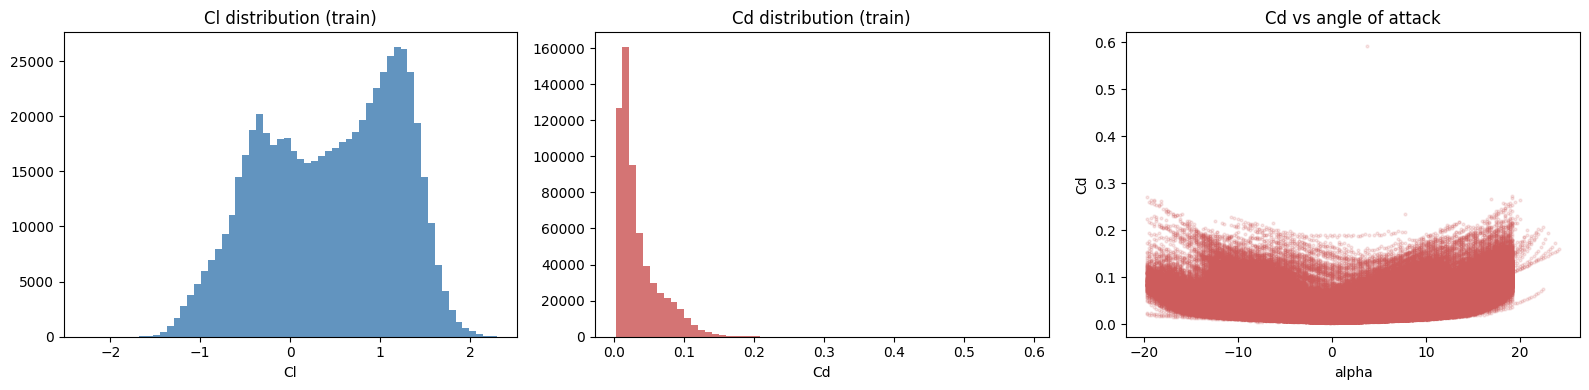

Cd range — train: 0.00265 to 0.59188
Cd range — test : 0.00338 to 0.31944


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(y_train["Cl"], bins=60, color="steelblue", alpha=0.85)
axes[0].set_title("Cl distribution (train)")
axes[0].set_xlabel("Cl")

axes[1].hist(y_train["Cd"], bins=60, color="indianred", alpha=0.85)
axes[1].set_title("Cd distribution (train)")
axes[1].set_xlabel("Cd")

axes[2].scatter(X_train["alpha"], y_train["Cd"], s=4, alpha=0.15, color="indianred")
axes[2].set_title("Cd vs angle of attack")
axes[2].set_xlabel("alpha")
axes[2].set_ylabel("Cd")

plt.tight_layout()
plt.show()

print("Cd range — train:", round(y_train["Cd"].min(), 5), "to", round(y_train["Cd"].max(), 5))
print("Cd range — test :", round(y_test["Cd"].min(), 5), "to", round(y_test["Cd"].max(), 5))


**Cd is heavily right-skewed** — most rows sit near-zero drag, with a long thin tail as `alpha` approaches stall. That tail is exactly where tree-based models struggle most (see Sections 10–11 below).

**📘 Note:** the printed ranges back this up directly — train Cd spans **0.00265 to 0.59188**, test Cd spans **0.00338 to 0.31944**. Keep this plot in mind for §11: it's the setup for the entire "Cd wall" investigation four sections later, and it's a strong candidate for the report's EDA section (Plot 1–3 below in the plot checklist, §21).

## 7. Helper Functions (Evaluation & Plotting)

In [7]:
results = {}          # {(model, target): {metrics...}} — dict so re-running a cell overwrites, not duplicates
trained_models = {}
predictions = {}


class PerTargetRegressor:
    """Wraps one already-fitted regressor per target so a set of single-output
    models (e.g. tuned LightGBM for Cl + tuned LightGBM for Cd) can be scored
    and plotted with the same helpers as a native multi-output model."""

    def __init__(self, models_by_target):
        self.models_by_target = models_by_target  # {target_name: fitted model}

    def predict(self, X):
        return np.column_stack([self.models_by_target[t].predict(X) for t in TARGETS])


def evaluate_and_store(name, model, X_eval, y_eval, elapsed=None):
    """Score a fitted model on a held-out set, store it for later comparison, and print a summary."""
    pred = model.predict(X_eval)
    predictions[name] = pred
    trained_models[name] = model

    for i, target in enumerate(TARGETS):
        mae = mean_absolute_error(y_eval.iloc[:, i], pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_eval.iloc[:, i], pred[:, i]))
        r2 = r2_score(y_eval.iloc[:, i], pred[:, i])
        results[(name, target)] = {
            "model": name, "target": target,
            "MAE": mae, "RMSE": rmse, "R2": r2,
            "train_time_min": elapsed / 60 if elapsed is not None else np.nan,
        }
        print(f"    {target:<3s}  MAE={mae:.6f}  RMSE={rmse:.6f}  R²={r2:.6f}")

    return pred


def plot_pred_vs_actual(y_eval, pred, model_name):
    """Predicted-vs-actual scatter per target with a y=x reference line.
    A flat cluster of points at the high end of a target — instead of hugging the
    diagonal — is the 'wall': the model can't extrapolate past what it saw in
    training, so every point landing in the same leaf gets the same prediction."""
    fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 5))
    if len(TARGETS) == 1:
        axes = [axes]
    for i, (ax, target) in enumerate(zip(axes, TARGETS)):
        y_true = y_eval.iloc[:, i]
        y_hat = pred[:, i]
        ax.scatter(y_true, y_hat, s=6, alpha=0.25, color="steelblue")
        lims = [min(y_true.min(), y_hat.min()), max(y_true.max(), y_hat.max())]
        ax.plot(lims, lims, "r--", linewidth=1.5, label="perfect fit")
        ax.set_xlabel(f"Actual {target}")
        ax.set_ylabel(f"Predicted {target}")
        ax.set_title(f"{model_name} — {target}")
        ax.legend()
    plt.tight_layout()
    plt.show()


def print_comparison_table(results_dict, model_order=None):
    """Render a markdown table of MAE/RMSE/R² per model/target, bolding the best value in each column."""
    metrics = ["MAE", "RMSE", "R2"]
    arrows = {"MAE": "↓", "RMSE": "↓", "R2": "↑"}

    results_df = pd.DataFrame(results_dict.values())
    pivot = results_df.pivot(index="model", columns="target", values=metrics)
    col_order = [(metric, target) for target in TARGETS for metric in metrics]
    pivot = pivot[col_order]

    if model_order:
        pivot = pivot.reindex([m for m in model_order if m in pivot.index])

    best_model = {}
    for metric, target in col_order:
        col = pivot[(metric, target)]
        best_model[(metric, target)] = col.idxmax() if metric == "R2" else col.idxmin()

    header = ["Model"] + [f"{target} {metric} {arrows[metric]}" for metric, target in col_order]
    align = ["---"] + [":---:" for _ in col_order]

    lines = [
        "| " + " | ".join(header) + " |",
        "| " + " | ".join(align) + " |",
    ]
    for model_name in pivot.index:
        row = [model_name]
        for metric, target in col_order:
            val = pivot.loc[model_name, (metric, target)]
            cell = f"{val:.6f}"
            if best_model[(metric, target)] == model_name:
                cell = f"**{cell}**"
            row.append(cell)
        lines.append("| " + " | ".join(row) + " |")

    display(Markdown("\n".join(lines)))
    return results_df


**📘 Note — what each helper does:**

- **`results = {}` / `trained_models = {}` / `predictions = {}`** — three module-level dictionaries that every model in §8 and §13 writes into via `evaluate_and_store()`, so the final comparison table (§9, §13) can be built from one place. ⚠️ **Heads-up, explained fully where it happens:** the name `results` gets reused for something completely different later on (cell 72 reassigns it to a plain list) — see the note at that cell for what this means.
- **`PerTargetRegressor`** — a small wrapper that holds *two independently-fitted* models (e.g. tuned LightGBM for `Cl` and tuned LightGBM for `Cd`, or even two *different* algorithms) behind one `.predict()` interface that returns both columns stacked together. This is what lets §13's tuned models — where each target can come from a different algorithm — be scored and plotted with exactly the same helper functions as a native multi-output model like `RandomForestRegressor`. Clean piece of design.
- **`evaluate_and_store(name, model, X_eval, y_eval, elapsed=None)`** — scores a fitted model on a held-out set (MAE/RMSE/R² per target), stores the prediction array, the fitted model object, and the metrics, then prints a one-line summary per target.
- **`plot_pred_vs_actual(...)`** — the predicted-vs-actual scatter with a $y=x$ reference line used after every model fit. Its own docstring already explains the "wall" pattern to watch for (flat horizontal cluster instead of hugging the diagonal) — that's the visual signature investigated fully in §11.
- **`print_comparison_table(...)`** — pivots the `results` dict into a Markdown table and **bolds the best value per column** (min for MAE/RMSE, max for R²). Nice touch — this is exactly the format used for the report tables throughout this notebook's added notes.

**🧮 Metric formulas, for the report:**

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}\lvert y_i-\hat y_i\rvert
\qquad
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
\qquad
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
$$

Lower MAE/RMSE is better; higher R² is better (1.0 = perfect fit).

## 8. Baseline Models

Same default-ish hyperparameters across the board first, so the comparison in Section 9 is apples-to-apples before any tuning.

### 8.1 Random Forest

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    8.4s
[Parallel(n_jobs=-1)]: Done 150 out of 150 | elapsed:   42.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.


RandomForest trained in 0.7 min



[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.7s
[Parallel(n_jobs=12)]: Done 150 out of 150 | elapsed:    7.3s finished


    Cl   MAE=0.095162  RMSE=0.161001  R²=0.954799
    Cd   MAE=0.007447  RMSE=0.015063  R²=0.767295


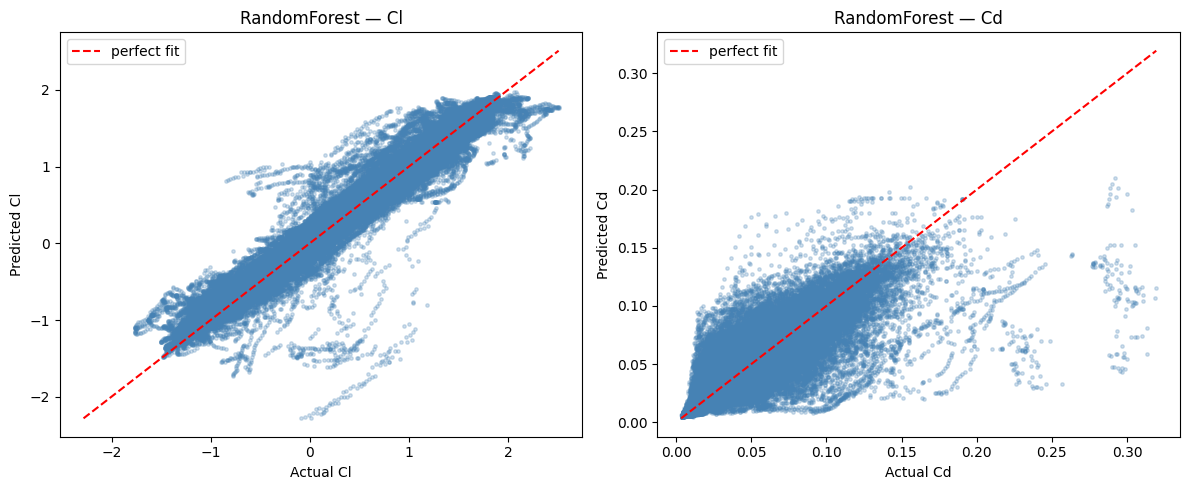

In [8]:
t0 = time.time()

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=None,
    n_jobs=-1,
    random_state=42,
    verbose=1,          # prints tree-building progress
)
rf_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f"RandomForest trained in {elapsed/60:.1f} min\n")

rf_pred = evaluate_and_store("RandomForest", rf_model, X_test, y_test, elapsed)
plot_pred_vs_actual(y_test, rf_pred, "RandomForest")


### 8.2 HistGradientBoosting

HistGradientBoosting trained in 0.1 min

    Cl   MAE=0.092520  RMSE=0.150998  R²=0.960241
    Cd   MAE=0.007517  RMSE=0.013398  R²=0.815911


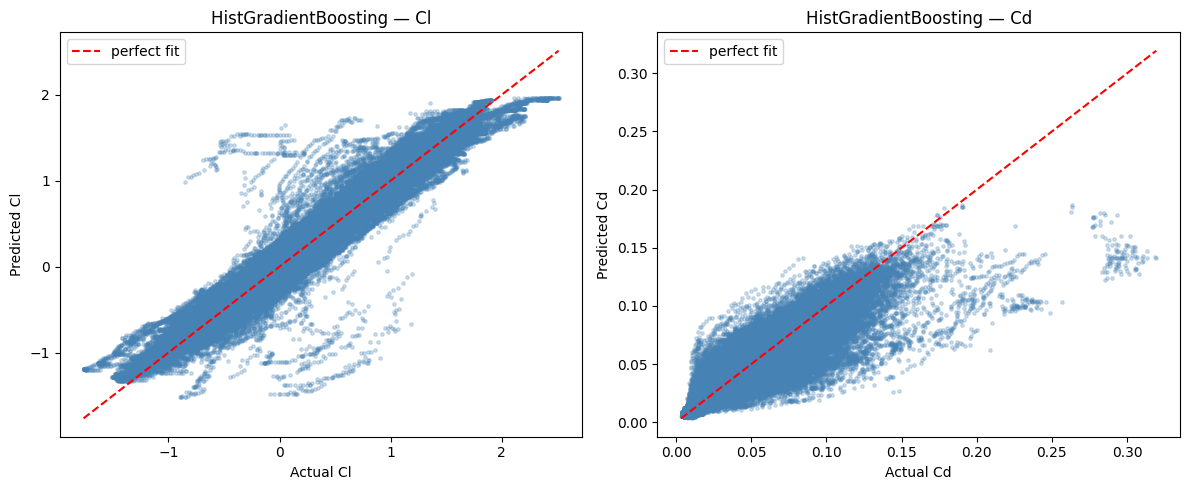

In [9]:
t0 = time.time()

histgb_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(
        random_state=42,
        verbose=1,      # prints per-iteration validation loss
    ),
    n_jobs=2,
)
histgb_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f"HistGradientBoosting trained in {elapsed/60:.1f} min\n")

histgb_pred = evaluate_and_store("HistGradientBoosting", histgb_model, X_test, y_test, elapsed)
plot_pred_vs_actual(y_test, histgb_pred, "HistGradientBoosting")


### 8.3 LightGBM

LightGBM trained in 0.1 min

    Cl   MAE=0.092031  RMSE=0.153987  R²=0.958651
    Cd   MAE=0.007006  RMSE=0.012425  R²=0.841668


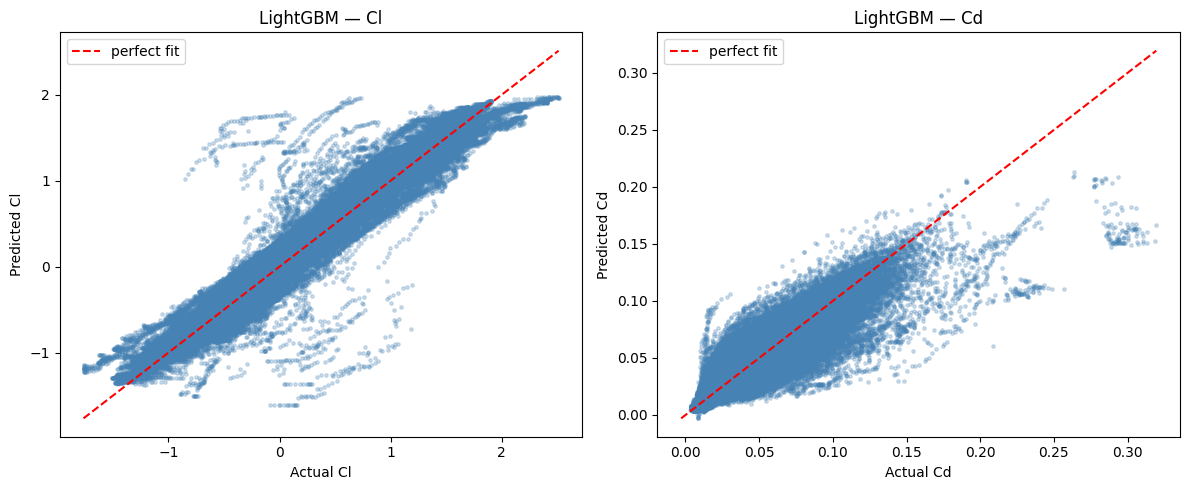

In [10]:
t0 = time.time()

lgb_model = MultiOutputRegressor(
    lgb.LGBMRegressor(
        n_estimators=300,
        n_jobs=1,
        random_state=42,
        verbose=-1,
    ),
    n_jobs=2,
)
lgb_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f"LightGBM trained in {elapsed/60:.1f} min\n")

lgb_pred = evaluate_and_store("LightGBM", lgb_model, X_test, y_test, elapsed)
plot_pred_vs_actual(y_test, lgb_pred, "LightGBM")


Watch the Cd panel above — this is usually where the 'wall' shows up first. Sections 10–11 dig into why, and Section 12.2 folds a fix into the tuned model.

### 8.4 XGBoost

XGBoost trained in 0.2 min

    Cl   MAE=0.091006  RMSE=0.145210  R²=0.963231
    Cd   MAE=0.007449  RMSE=0.013402  R²=0.815797


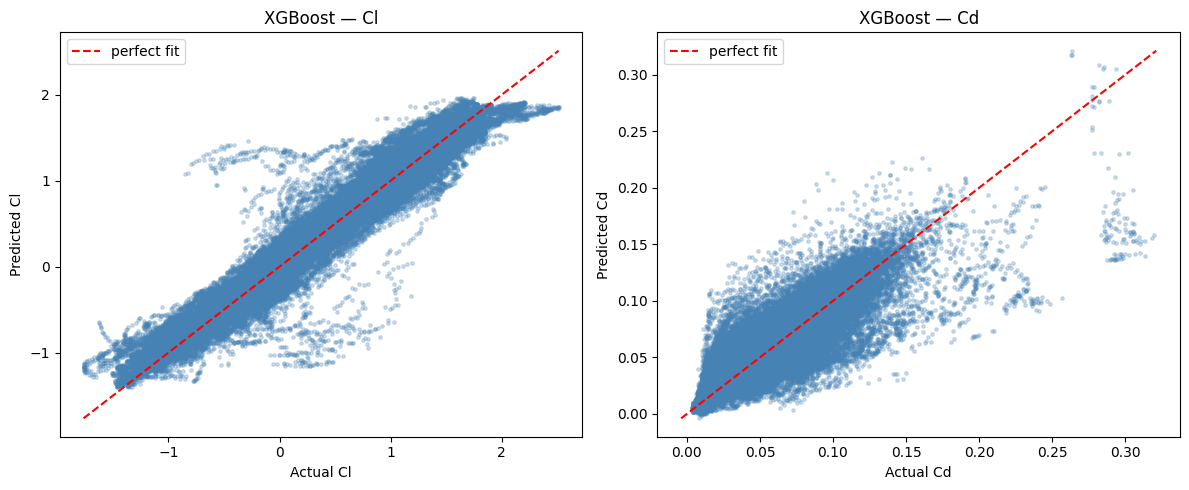

In [11]:
t0 = time.time()

xgb_model = MultiOutputRegressor(
    xgb.XGBRegressor(
        n_estimators=300,
        n_jobs=1,
        random_state=42,
        verbosity=1,
    ),
    n_jobs=2,
)
xgb_model.fit(X_train, y_train)
elapsed = time.time() - t0
print(f"XGBoost trained in {elapsed/60:.1f} min\n")

xgb_pred = evaluate_and_store("XGBoost", xgb_model, X_test, y_test, elapsed)
plot_pred_vs_actual(y_test, xgb_pred, "XGBoost")


## 9. Model Comparison (Baseline)

| Model | Cl MAE ↓ | Cl RMSE ↓ | Cl R2 ↑ | Cd MAE ↓ | Cd RMSE ↓ | Cd R2 ↑ |
| --- | :---: | :---: | :---: | :---: | :---: | :---: |
| RandomForest | 0.095162 | 0.161001 | 0.954799 | 0.007447 | 0.015063 | 0.767295 |
| HistGradientBoosting | 0.092520 | 0.150998 | 0.960241 | 0.007517 | 0.013398 | 0.815911 |
| LightGBM | 0.092031 | 0.153987 | 0.958651 | **0.007006** | **0.012425** | **0.841668** |
| XGBoost | **0.091006** | **0.145210** | **0.963231** | 0.007449 | 0.013402 | 0.815797 |

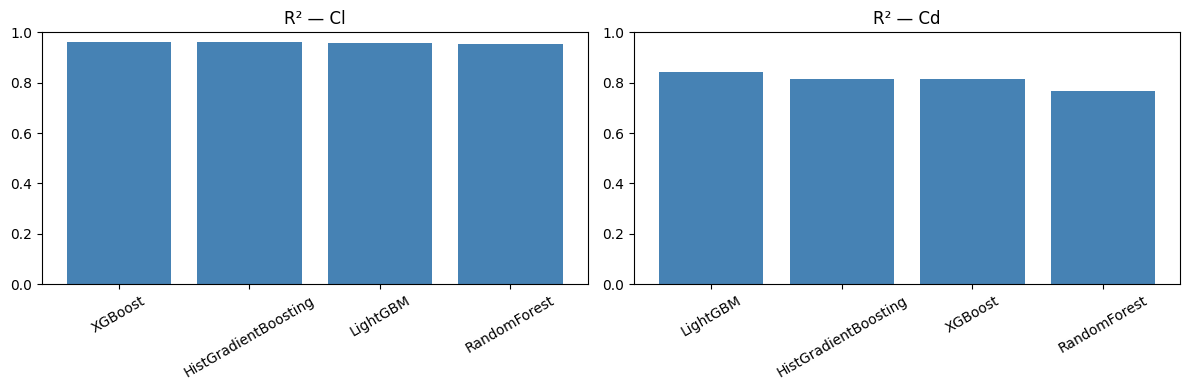

In [12]:
results_df = print_comparison_table(
    results,
    model_order=["RandomForest", "HistGradientBoosting", "LightGBM", "XGBoost"],
)

fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4))
for ax, target in zip(axes, TARGETS):
    sub = results_df[results_df["target"] == target].sort_values("R2", ascending=False)
    ax.bar(sub["model"], sub["R2"], color="steelblue")
    ax.set_title(f"R² — {target}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


**📊 Report table — Table 2: baseline model comparison** (default-ish hyperparameters, held-out test set — reproduced from this cell's own rendered output)

| Model | Cl MAE ↓ | Cl RMSE ↓ | Cl R² ↑ | Cd MAE ↓ | Cd RMSE ↓ | Cd R² ↑ |
|---|---:|---:|---:|---:|---:|---:|
| RandomForest | 0.095162 | 0.161001 | 0.954799 | 0.007447 | 0.015063 | 0.767295 |
| HistGradientBoosting | 0.092520 | 0.150998 | 0.960241 | 0.007517 | 0.013398 | 0.815911 |
| LightGBM | 0.092031 | 0.153987 | 0.958651 | **0.007006** | **0.012425** | **0.841668** |
| XGBoost | **0.091006** | **0.145210** | **0.963231** | 0.007449 | 0.013402 | 0.815797 |

**📘 Reading it:** XGBoost is the best *baseline* for `Cl`; LightGBM is the best baseline for `Cd`. Every model's `Cd` R² is noticeably weaker than its `Cl` R² (≈0.77–0.84 vs ≈0.95–0.96) — that gap is exactly what §11 investigates next.

## 10. Faster Subsample for Tuning

Searching hyperparameters on the full training set would take a long time. Sample by *airfoil* (not row) so grouping stays intact, tune on this subset, then retrain the winners on the full data in Section 13.

In [13]:
sample_splitter = GroupShuffleSplit(n_splits=1, train_size=0.25, random_state=42)
sample_idx, _ = next(sample_splitter.split(X_train, y_train, groups=train_groups))

X_search = X_train.iloc[sample_idx]
y_search = y_train.iloc[sample_idx]
groups_search = train_groups.iloc[sample_idx]

print(f"Search set: {X_search.shape[0]:,} rows, {groups_search.nunique()} airfoils")


Search set: 159,047 rows, 163 airfoils


**📘 Note:** tuning on all 616,487 training rows would be slow to search over many trials, so a 25%-*by-airfoil* subsample is drawn here (159,047 rows / 163 airfoils, per this cell's own printout) — sampled by group, same discipline as §5, so the tuning folds in §12 still can't leak an airfoil between a fold's train and validation half. The winning hyperparameters are then used to retrain on the *full* training set in §13.

## 11. Diagnosing & Fixing the LightGBM Cd "Wall"

Every tree-based model here (RF, HistGB, LightGBM, XGBoost) predicts a **constant value per leaf** — the average target of whichever training rows landed there. That means none of them can predict outside the range of `Cd` seen during training. If a test airfoil pushes `alpha` further into stall than anything in the training set, all of those high-`Cd` rows fall into the same leaf and come out as the same flat value — a "wall" in the predicted-vs-actual plot instead of a diagonal line. Cd suffers more than Cl here because its stall-region tail is thin and sits right at (or past) the edge of the training distribution, so a plain booster has very little to learn from up there.

Two independent fixes to try below: **(a)** `linear_tree=True` in LightGBM, which fits a small linear model in each leaf instead of a constant, so it can extrapolate a slope instead of flattening out; **(b)** a `log1p` transform on Cd, which compresses the long tail so the loss function stops effectively ignoring it.

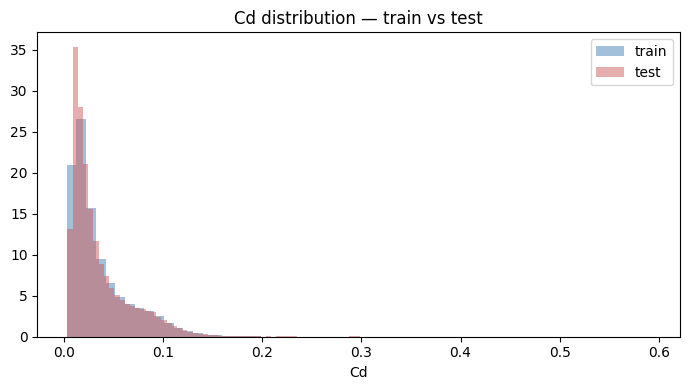

Test rows with Cd beyond the training max: 0 / 152055


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y_train["Cd"], bins=60, alpha=0.5, label="train", color="steelblue", density=True)
ax.hist(y_test["Cd"], bins=60, alpha=0.5, label="test", color="indianred", density=True)
ax.set_xlabel("Cd")
ax.set_title("Cd distribution — train vs test")
ax.legend()
plt.tight_layout()
plt.show()

print("Test rows with Cd beyond the training max:",
      (y_test["Cd"] > y_train["Cd"].max()).sum(), "/", len(y_test))


baseline             R²(Cd) = 0.78922
linear_tree=True     R²(Cd) = -1954.14165
log1p(Cd) target     R²(Cd) = 0.79184


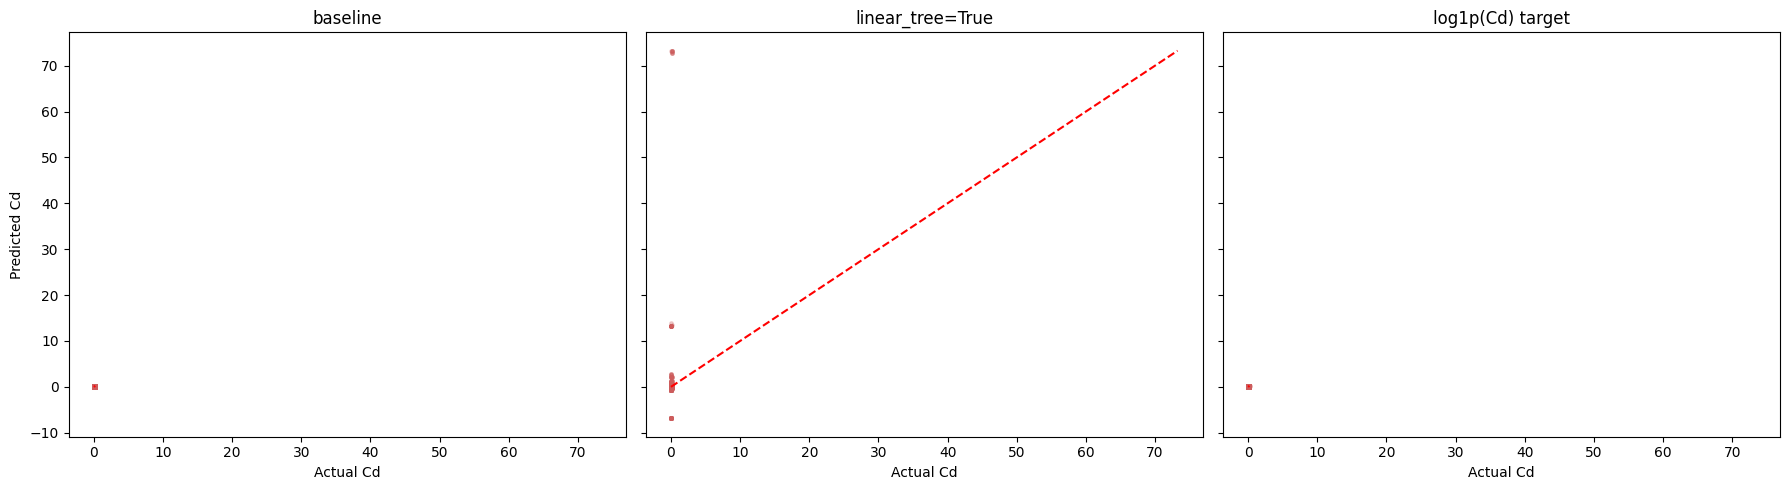

In [15]:
diag_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
fit_i, val_i = next(diag_split.split(X_search, y_search["Cd"], groups=groups_search))

X_fit, X_val = X_search.iloc[fit_i], X_search.iloc[val_i]
y_fit, y_val = y_search["Cd"].iloc[fit_i], y_search["Cd"].iloc[val_i]

wall_results = {}

# 1) baseline LightGBM
m_base = lgb.LGBMRegressor(n_estimators=300, random_state=42, n_jobs=-1, verbose=-1)
m_base.fit(X_fit, y_fit)
wall_results["baseline"] = m_base.predict(X_val)

# 2) linear_tree=True — fits a small linear model per leaf instead of a constant
m_lt = lgb.LGBMRegressor(n_estimators=300, random_state=42, n_jobs=-1, verbose=-1, linear_tree=True)
m_lt.fit(X_fit, y_fit)
wall_results["linear_tree=True"] = m_lt.predict(X_val)

# 3) log1p target transform — compresses the long right tail before fitting
m_log = lgb.LGBMRegressor(n_estimators=300, random_state=42, n_jobs=-1, verbose=-1)
m_log.fit(X_fit, np.log1p(y_fit))
wall_results["log1p(Cd) target"] = np.expm1(m_log.predict(X_val))

for name, pred in wall_results.items():
    print(f"{name:<20s} R²(Cd) = {r2_score(y_val, pred):.5f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, wall_results.items()):
    ax.scatter(y_val, pred, s=6, alpha=0.25, color="indianred")
    lims = [y_val.min(), max(y_val.max(), pred.max())]
    ax.plot(lims, lims, "r--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Actual Cd")
axes[0].set_ylabel("Predicted Cd")
plt.tight_layout()
plt.show()


**📊 Report table — Table 3: Cd "wall" ablation** (diagnostic validation slice, numbers from this cell's own printed output)

| Approach | Cd R² |
|---|---:|
| Baseline LightGBM | 0.78922 |
| `linear_tree=True` | **−1954.14165** (rejected — wildly unstable on this data) |
| `log1p(Cd)` target transform | 0.79184 (marginal improvement) |

**📘 Note — a precise way to phrase this finding for a report:** this cell also prints `Test rows with Cd beyond the training max: 0 / 152,055` — worth being careful with that number. It does **not** mean the "wall" is caused by test points literally falling outside the training range (none do, here). The more accurate explanation: every model above is tree-based, and a tree predicts a **constant value per leaf** — the average of whichever training rows land there. `Cd`'s right-hand tail (near stall) is thin, so a handful of high-`Cd` training rows often end up sharing a leaf with many more moderate-`Cd` rows, and *any* test point that lands in that same leaf gets pulled toward the average rather than the extreme — a flat "wall" in the predicted-vs-actual plot rather than a diagonal, even without any point being technically out-of-range. A safe, accurate sentence for the limitations section: *"Tree-based models produce piecewise-constant predictions and lose precision in sparse regions of the feature space — here, the thin high-drag tail near stall — even when those regions are technically within the training range."*

Both ablation results are echoed independently later: the Optuna search for LightGBM in §12.2 is completely free to pick `linear_tree=True` if it helps, and it independently lands on `linear_tree=False` for **both** targets — a nice internal consistency check that this ablation's conclusion holds up under full tuning, not just on this diagnostic slice.

Whichever panel above hugs the diagonal furthest into the tail is worth carrying into tuning. `linear_tree` is already wired in as a choice Optuna can make for itself in Section 12.2 below — if the log1p transform wins instead, swap it in there the same way it's used here (fit on `np.log1p(y)`, invert with `np.expm1(...)` before scoring).

## 12. Hyperparameter Tuning

All tuning below runs on the `X_search` / `y_search` subsample from Section 10, with `GroupKFold` so no airfoil leaks between fold train/val.

### 12.1 Random Forest

In [16]:
cv = GroupKFold(n_splits=3)

rf_param_dist = {
    "n_estimators": [150, 250, 350, 500],
    "max_depth": [None, 15, 25, 35],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", 0.5, 0.8, 1.0],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=20,
    scoring="r2",
    cv=cv,
    n_jobs=1,       # RF already uses all cores per fit; avoid oversubscribing
    verbose=2,
    random_state=42,
)

rf_search.fit(X_search, y_search, groups=groups_search)

print("Best RF params:", rf_search.best_params_)
print("Best RF CV R² :", rf_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END max_depth=35, max_features=0.8, min_samples_leaf=2, n_estimators=150; total time=   3.0s
[CV] END max_depth=35, max_features=0.8, min_samples_leaf=2, n_estimators=150; total time=   3.0s
[CV] END max_depth=35, max_features=0.8, min_samples_leaf=2, n_estimators=150; total time=   3.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=350; total time=   3.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=350; total time=   4.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=350; total time=   4.7s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=8, n_estimators=500; total time=   4.4s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=8, n_estimators=500; total time=   4.2s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=8, n_estimators=500; total time=   4.2s
[CV] END max_depth=35, max_features=sqrt, min

**📘 Note:** `RandomizedSearchCV`'s default `scoring="r2"` on a two-column target (`y_search` has both `Cl` and `Cd`) uses scikit-learn's `multioutput='uniform_average'` R² — i.e. **one blended Cl+Cd number**, not a per-target score. That's why Random Forest's row in the tuning table below only has one CV score, while LightGBM/XGBoost/HistGB (tuned with Optuna, one study per target) have two. Worth a footnote if Table 4 goes into the report — it isn't a like-for-like comparison across rows.

Best params found here (from this cell's own printout): `n_estimators=500, min_samples_leaf=2, max_features='sqrt', max_depth=35` → blended CV R² ≈ **0.88583**.

### 12.2 LightGBM (tuned per target — `linear_tree` included as a search choice)

In [17]:
def make_lgb_objective(target_name):
    y_col = y_search[target_name]

    def objective(trial):
        params = dict(
            n_estimators=2000,   # ceiling; early stopping finds the real count
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            num_leaves=trial.suggest_int("num_leaves", 15, 255),
            min_child_samples=trial.suggest_int("min_child_samples", 5, 200),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            linear_tree=trial.suggest_categorical("linear_tree", [False, True]),
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        )

        scores = []
        for tr_idx, val_idx in GroupKFold(n_splits=3).split(X_search, y_col, groups=groups_search):
            X_tr, X_val = X_search.iloc[tr_idx], X_search.iloc[val_idx]
            y_tr, y_val = y_col.iloc[tr_idx], y_col.iloc[val_idx]

            model = lgb.LGBMRegressor(**params)
            model.fit(
                X_tr, y_tr,
                eval_set=[(X_val, y_val)],
                callbacks=[lgb.early_stopping(50, verbose=False)],
            )
            scores.append(r2_score(y_val, model.predict(X_val)))

        return np.mean(scores)

    return objective


study_cl = optuna.create_study(direction="maximize", study_name="lgb_Cl")
study_cl.optimize(make_lgb_objective("Cl"), n_trials=40, show_progress_bar=True)

study_cd = optuna.create_study(direction="maximize", study_name="lgb_Cd")
study_cd.optimize(make_lgb_objective("Cd"), n_trials=40, show_progress_bar=True)

print("Best Cl params:", study_cl.best_params, "→ R² =", study_cl.best_value)
print("Best Cd params:", study_cd.best_params, "→ R² =", study_cd.best_value)


[I 2026-09-14 13:34:50,633] A new study created in memory with name: lgb_Cl


  0%|          | 0/40 [00:00<?, ?it/s]

c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-14 13:35:11,295] Trial 0 finished with value: 0.965551319260692 and parameters: {'learning_rate': 0.025361053573981003, 'num_leaves': 210, 'min_child_samples': 68, 'subsample': 0.8849240708020554, 'colsample_bytree': 0.618509142299688, 'reg_alpha': 0.05597667827087758, 'reg_lambda': 1.2018065698891424e-06, 'linear_tree': False}. Best is trial 0 with value: 0.965551319260692.


c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

[I 2026-09-14 13:45:06,735] Trial 37 finished with value: 0.810655844703498 and parameters: {'learning_rate': 0.017217325700680287, 'num_leaves': 104, 'min_child_samples': 84, 'subsample': 0.9283328300558493, 'colsample_bytree': 0.9168460854716952, 'reg_alpha': 3.612495962424577e-05, 'reg_lambda': 8.476205092200967, 'linear_tree': False}. Best is trial 26 with value: 0.8132304179047543.


c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-14 13:45:14,849] Trial 38 finished with value: 0.8107113219958734 and parameters: {'learning_rate': 0.012974670033864986, 'num_leaves': 31, 'min_child_samples': 105, 'subsample': 0.975380714009992, 'colsample_bytree': 0.9443447149205001, 'reg_alpha': 1.8052554149035137e-05, 'reg_lambda': 1.6092882862121536, 'linear_tree': False}. Best is trial 26 with value: 0.8132304179047543.


c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-09-14 13:45:20,359] Trial 39 finished with value: 0.8133870317448552 and parameters: {'learning_rate': 0.018399484821295015, 'num_leaves': 78, 'min_child_samples': 99, 'subsample': 0.9176267258465369, 'colsample_bytree': 0.9625564889475594, 'reg_alpha': 4.533260000563295e-08, 'reg_lambda': 0.0360718378441897, 'linear_tree': False}. Best is trial 39 with value: 0.8133870317448552.
Best Cl params: {'learning_rate': 0.02072734005029392, 'num_leaves': 97, 'min_child_samples': 167, 'subsample': 0.8413859002583993, 'colsample_bytree': 0.9501876115231493, 'reg_alpha': 0.000537565052015638, 'reg_lambda': 4.135998029227402e-07, 'linear_tree': False} → R² = 0.9722105261479296
Best Cd params: {'learning_rate': 0.018399484821295015, 'num_leaves': 78, 'min_child_samples': 99, 'subsample': 0.9176267258465369, 'colsample_bytree': 0.9625564889475594, 'reg_alpha': 4.533260000563295e-08, 'reg_lambda': 0.0360718378441897, 'linear_tree': False} → R² = 0.8133870317448552


**📘 Note:** Optuna's TPE sampler runs 40 trials **per target** (80 total), each trial doing a full `GroupKFold(3)` cross-validation with early stopping inside every fold. Best results (from this cell's own printout):

| Target | Key params | CV R² |
|---|---|---:|
| Cl | `learning_rate≈0.0207, num_leaves=97, min_child_samples=167, linear_tree=False` | 0.97221 |
| Cd | `learning_rate≈0.0184, num_leaves=78, min_child_samples=99, linear_tree=False` | 0.81339 |

Note `linear_tree=False` won for both targets — consistent with the §11 ablation's finding that `linear_tree=True` was unstable on this data, now confirmed under a full 40-trial search rather than just the one-shot diagnostic comparison.

### 12.3 XGBoost (tuned per target)

In [18]:
def make_xgb_objective(target_name):
    y_col = y_search[target_name]

    def objective(trial):
        params = dict(
            n_estimators=2000,
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 12),
            min_child_weight=trial.suggest_float("min_child_weight", 1e-2, 20.0, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            random_state=42,
            n_jobs=-1,
            eval_metric="rmse",
            early_stopping_rounds=50,   # XGBoost 2.x: lives in the constructor, not .fit()
        )

        scores = []
        for tr_idx, val_idx in GroupKFold(n_splits=3).split(X_search, y_col, groups=groups_search):
            X_tr, X_val = X_search.iloc[tr_idx], X_search.iloc[val_idx]
            y_tr, y_val = y_col.iloc[tr_idx], y_col.iloc[val_idx]

            model = xgb.XGBRegressor(**params)
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
            scores.append(r2_score(y_val, model.predict(X_val)))

        return np.mean(scores)

    return objective


study_cl_xgb = optuna.create_study(direction="maximize", study_name="xgb_Cl")
study_cl_xgb.optimize(make_xgb_objective("Cl"), n_trials=40, show_progress_bar=True)

study_cd_xgb = optuna.create_study(direction="maximize", study_name="xgb_Cd")
study_cd_xgb.optimize(make_xgb_objective("Cd"), n_trials=40, show_progress_bar=True)

print("Best Cl params:", study_cl_xgb.best_params, "→ R² =", study_cl_xgb.best_value)
print("Best Cd params:", study_cd_xgb.best_params, "→ R² =", study_cd_xgb.best_value)


[I 2026-09-14 13:45:20,405] A new study created in memory with name: xgb_Cl


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-09-14 13:45:24,580] Trial 0 finished with value: 0.9680817430126806 and parameters: {'learning_rate': 0.0630748787026043, 'max_depth': 7, 'min_child_weight': 15.104255469689466, 'subsample': 0.7383904762481339, 'colsample_bytree': 0.8407187823405784, 'reg_alpha': 3.0886968362174983e-06, 'reg_lambda': 2.735100195327243e-06}. Best is trial 0 with value: 0.9680817430126806.
[I 2026-09-14 13:45:37,284] Trial 1 finished with value: 0.9649119304203948 and parameters: {'learning_rate': 0.015349232484910151, 'max_depth': 9, 'min_child_weight': 0.993606131538339, 'subsample': 0.5188619491528336, 'colsample_bytree': 0.6055674787475557, 'reg_alpha': 2.7751420554844187e-05, 'reg_lambda': 6.735383227821207e-07}. Best is trial 0 with value: 0.9680817430126806.
[I 2026-09-14 13:45:47,334] Trial 2 finished with value: 0.9659180617270816 and parameters: {'learning_rate': 0.018299473713435925, 'max_depth': 6, 'min_child_weight': 10.254684178286652, 'subsample': 0.7378503384618649, 'colsample_byt

[I 2026-09-14 13:47:55,815] A new study created in memory with name: xgb_Cd


[I 2026-09-14 13:47:55,809] Trial 39 finished with value: 0.9690989406580254 and parameters: {'learning_rate': 0.12482420692702906, 'max_depth': 7, 'min_child_weight': 0.250379896378217, 'subsample': 0.5905921559849255, 'colsample_bytree': 0.8693786857962059, 'reg_alpha': 0.002076780725897002, 'reg_lambda': 8.98898949144816e-07}. Best is trial 36 with value: 0.9703388872214873.


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-09-14 13:48:09,727] Trial 0 finished with value: 0.8005496784745075 and parameters: {'learning_rate': 0.0260823141056994, 'max_depth': 5, 'min_child_weight': 0.038772418589437835, 'subsample': 0.5660868597198925, 'colsample_bytree': 0.7858275783046527, 'reg_alpha': 0.33105865140922813, 'reg_lambda': 2.1274724826123018e-06}. Best is trial 0 with value: 0.8005496784745075.
[I 2026-09-14 13:48:11,742] Trial 1 finished with value: 0.7992911524121165 and parameters: {'learning_rate': 0.08336319187017507, 'max_depth': 7, 'min_child_weight': 0.1067655800115597, 'subsample': 0.5050725317421183, 'colsample_bytree': 0.7900755585268506, 'reg_alpha': 2.849157353494636e-05, 'reg_lambda': 7.052398210397754e-07}. Best is trial 0 with value: 0.8005496784745075.
[I 2026-09-14 13:48:21,998] Trial 2 finished with value: 0.7836900904892214 and parameters: {'learning_rate': 0.04399729279068946, 'max_depth': 4, 'min_child_weight': 3.2659130644870826, 'subsample': 0.9716455752987756, 'colsample_bytre

**📘 Note:** the constructor comment (`# XGBoost 2.x: lives in the constructor, not .fit()`) is worth expanding on for anyone reading this later — in XGBoost's older API, `early_stopping_rounds` was passed to `.fit()`; from XGBoost 2.0 onward it moved into the model constructor (`xgb.XGBRegressor(..., early_stopping_rounds=50)`), which is what this code correctly does. Best results (from this cell's own printout):

| Target | Key params | CV R² |
|---|---|---:|
| Cl | `learning_rate≈0.098, max_depth=7, min_child_weight≈0.577` | 0.97034 |
| Cd | `learning_rate≈0.032, max_depth=9, min_child_weight≈0.123` | 0.81085 |

### 12.4 HistGradientBoosting (tuned per target)

Its built-in early stopping carves out its own validation split, but that split isn't group-aware — it can leak airfoils between HistGB's internal train/val chunks. Safer to turn it off and tune `max_iter` explicitly through the same `GroupKFold` loop as the others (fewer trials than LightGBM/XGBoost since every trial here is a full fit, no early stopping to cut it short).

In [19]:
def make_histgb_objective(target_name):
    y_col = y_search[target_name]

    def objective(trial):
        params = dict(
            max_iter=trial.suggest_int("max_iter", 100, 800, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 255),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 100),
            l2_regularization=trial.suggest_float("l2_regularization", 1e-8, 10.0, log=True),
            random_state=42,
            early_stopping=False,
        )

        scores = []
        for tr_idx, val_idx in GroupKFold(n_splits=3).split(X_search, y_col, groups=groups_search):
            X_tr, X_val = X_search.iloc[tr_idx], X_search.iloc[val_idx]
            y_tr, y_val = y_col.iloc[tr_idx], y_col.iloc[val_idx]

            model = HistGradientBoostingRegressor(**params)
            model.fit(X_tr, y_tr)
            scores.append(r2_score(y_val, model.predict(X_val)))

        return np.mean(scores)

    return objective


study_cl_hgb = optuna.create_study(direction="maximize", study_name="histgb_Cl")
study_cl_hgb.optimize(make_histgb_objective("Cl"), n_trials=25, show_progress_bar=True)

study_cd_hgb = optuna.create_study(direction="maximize", study_name="histgb_Cd")
study_cd_hgb.optimize(make_histgb_objective("Cd"), n_trials=25, show_progress_bar=True)

print("Best Cl params:", study_cl_hgb.best_params, "→ R² =", study_cl_hgb.best_value)
print("Best Cd params:", study_cd_hgb.best_params, "→ R² =", study_cd_hgb.best_value)


[I 2026-09-14 13:52:07,435] A new study created in memory with name: histgb_Cl


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-09-14 13:52:23,376] Trial 0 finished with value: 0.9708314607802578 and parameters: {'max_iter': 500, 'learning_rate': 0.01832109713014358, 'max_leaf_nodes': 126, 'min_samples_leaf': 17, 'l2_regularization': 9.039387713460808e-06}. Best is trial 0 with value: 0.9708314607802578.
[I 2026-09-14 13:53:07,198] Trial 1 finished with value: 0.9695424389253251 and parameters: {'max_iter': 800, 'learning_rate': 0.016064034284133447, 'max_leaf_nodes': 244, 'min_samples_leaf': 27, 'l2_regularization': 0.0004010789630667087}. Best is trial 0 with value: 0.9708314607802578.
[I 2026-09-14 13:53:10,613] Trial 2 finished with value: 0.9706307855289 and parameters: {'max_iter': 150, 'learning_rate': 0.1354956021482279, 'max_leaf_nodes': 84, 'min_samples_leaf': 15, 'l2_regularization': 0.0026291638374481385}. Best is trial 0 with value: 0.9708314607802578.
[I 2026-09-14 13:53:13,290] Trial 3 finished with value: 0.9709556355952224 and parameters: {'max_iter': 100, 'learning_rate': 0.06506400886

[I 2026-09-14 13:56:17,940] A new study created in memory with name: histgb_Cd


[I 2026-09-14 13:56:17,937] Trial 24 finished with value: 0.9693839965883203 and parameters: {'max_iter': 250, 'learning_rate': 0.047806963312729704, 'max_leaf_nodes': 25, 'min_samples_leaf': 35, 'l2_regularization': 0.00024144002907384974}. Best is trial 20 with value: 0.9711615522346446.


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-09-14 13:56:47,619] Trial 0 finished with value: 0.8075995017766503 and parameters: {'max_iter': 700, 'learning_rate': 0.02100138727538804, 'max_leaf_nodes': 201, 'min_samples_leaf': 68, 'l2_regularization': 7.3623832238308375e-06}. Best is trial 0 with value: 0.8075995017766503.
[I 2026-09-14 13:56:52,883] Trial 1 finished with value: 0.806748564065925 and parameters: {'max_iter': 350, 'learning_rate': 0.10255778197873691, 'max_leaf_nodes': 49, 'min_samples_leaf': 35, 'l2_regularization': 1.7175761667512928}. Best is trial 0 with value: 0.8075995017766503.
[I 2026-09-14 13:57:01,742] Trial 2 finished with value: 0.8087229674643414 and parameters: {'max_iter': 150, 'learning_rate': 0.04551050111214786, 'max_leaf_nodes': 254, 'min_samples_leaf': 51, 'l2_regularization': 2.0293702224592196e-08}. Best is trial 2 with value: 0.8087229674643414.
[I 2026-09-14 13:57:04,007] Trial 3 finished with value: 0.7797643650146648 and parameters: {'max_iter': 150, 'learning_rate': 0.0203062837

**📘 Note:** HistGradientBoosting gets a smaller budget (25 trials/target vs 40 for the other boosters) because its *built-in* early stopping carves out its own internal validation split that isn't group-aware — it could leak an airfoil between HistGB's own train/val chunks. Turning it off (`early_stopping=False`) and instead tuning `max_iter` explicitly through the same `GroupKFold` loop as the others keeps the grouping discipline intact, at the cost of every trial being a full, more expensive fit (no early exit). Best results (from this cell's own printout):

| Target | Key params | CV R² |
|---|---|---:|
| Cl | `max_iter=400, learning_rate≈0.033, max_leaf_nodes=80` | 0.97116 |
| Cd | `max_iter=200, learning_rate≈0.040, max_leaf_nodes=85` | 0.81318 |

**📊 Report table — Table 4: hyperparameter tuning summary (all four models)**

| Model | Method | Budget | Best Cl config | Cl CV R² | Best Cd config | Cd CV R² |
|---|---|---|---|---:|---|---:|
| Random Forest | RandomizedSearchCV | 20 × 3 folds | `n_estimators=500, min_samples_leaf=2, max_features='sqrt', max_depth=35` | 0.88583* | *(same config, blended)* | *(same)* |
| LightGBM | Optuna | 40 trials/target | `lr≈0.0207, num_leaves=97, min_child_samples=167` | 0.97221 | `lr≈0.0184, num_leaves=78, min_child_samples=99` | 0.81339 |
| XGBoost | Optuna | 40 trials/target | `lr≈0.098, max_depth=7` | 0.97034 | `lr≈0.032, max_depth=9` | 0.81085 |
| HistGradientBoosting | Optuna | 25 trials/target | `max_iter=400, lr≈0.033` | 0.97116 | `max_iter=200, lr≈0.040` | 0.81318 |

\* *RF's score is a single blended Cl+Cd R² (see the note above at cell 36) — not directly comparable to the per-target numbers in the other three rows.*

## 13. Final Retrain on Full Data, Evaluate & Save

In [20]:
gss_final = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
fit_idx, val_idx = next(gss_final.split(X_train, y_train, groups=train_groups))


**📘 Note:** this carves a 90/10 split of the *training* airfoils only (the untouched test set from §5 is not involved here) purely so LightGBM and XGBoost have a validation slice to early-stop against while refitting their tuned configuration on (almost) the full training set. HistGB and Random Forest, below, don't use this split — see the note after cell 50 for why that matters.

**LightGBM (tuned)**

c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[444]	valid_0's l2: 0.0122719
LightGBM Cl: stopped at iteration 444
Training until validation scores don't improve for 50 rounds


c:\Users\lavish\Desktop\AeroFoil\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Early stopping, best iteration is:
[688]	valid_0's l2: 0.000116021
LightGBM Cd: stopped at iteration 688
    Cl   MAE=0.089825  RMSE=0.149236  R²=0.961163
    Cd   MAE=0.006887  RMSE=0.012685  R²=0.834978


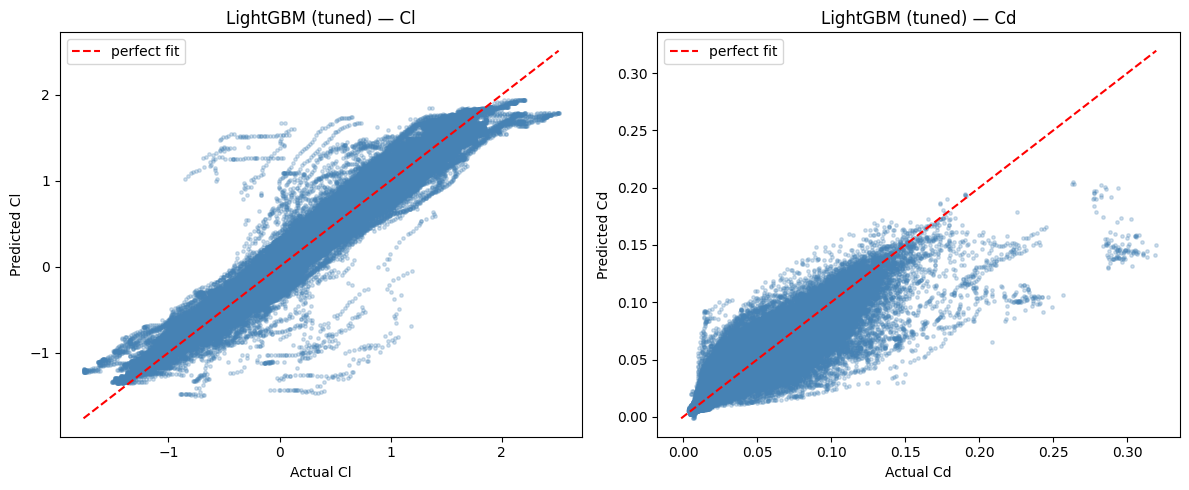

In [21]:
lgb_tuned = {}
for target, study in [("Cl", study_cl), ("Cd", study_cd)]:
    params = {**study.best_params, "n_estimators": 2000, "random_state": 42, "n_jobs": -1, "verbose": -1}
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train.iloc[fit_idx], y_train[target].iloc[fit_idx],
        eval_set=[(X_train.iloc[val_idx], y_train[target].iloc[val_idx])],
        callbacks=[lgb.early_stopping(50, verbose=True)],
    )
    lgb_tuned[target] = model
    print(f"LightGBM {target}: stopped at iteration {model.best_iteration_}")

lgb_tuned_model = PerTargetRegressor(lgb_tuned)
lgb_tuned_pred = evaluate_and_store("LightGBM (tuned)", lgb_tuned_model, X_test, y_test)
plot_pred_vs_actual(y_test, lgb_tuned_pred, "LightGBM (tuned)")


**XGBoost (tuned)**

XGBoost Cl: stopped at iteration 209
XGBoost Cd: stopped at iteration 422
    Cl   MAE=0.090344  RMSE=0.142695  R²=0.964493
    Cd   MAE=0.007009  RMSE=0.013127  R²=0.823260


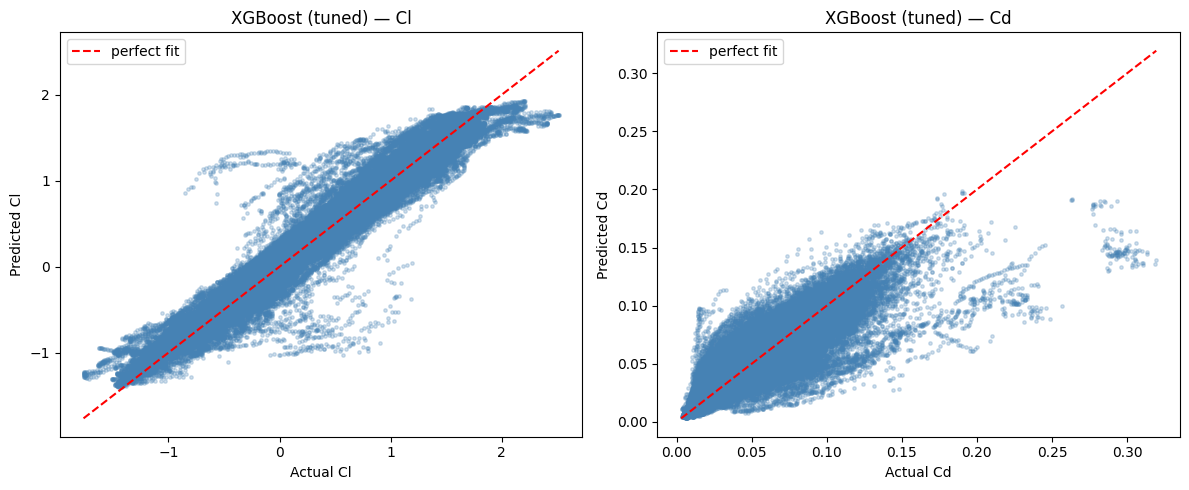

In [22]:
xgb_tuned = {}
for target, study in [("Cl", study_cl_xgb), ("Cd", study_cd_xgb)]:
    params = {**study.best_params, "n_estimators": 2000, "random_state": 42, "n_jobs": -1,
              "eval_metric": "rmse", "early_stopping_rounds": 50}
    model = xgb.XGBRegressor(**params)
    model.fit(
        X_train.iloc[fit_idx], y_train[target].iloc[fit_idx],
        eval_set=[(X_train.iloc[val_idx], y_train[target].iloc[val_idx])],
        verbose=False,
    )
    xgb_tuned[target] = model
    print(f"XGBoost {target}: stopped at iteration {model.best_iteration}")

xgb_tuned_model = PerTargetRegressor(xgb_tuned)
xgb_tuned_pred = evaluate_and_store("XGBoost (tuned)", xgb_tuned_model, X_test, y_test)
plot_pred_vs_actual(y_test, xgb_tuned_pred, "XGBoost (tuned)")


**HistGradientBoosting (tuned)**

    Cl   MAE=0.089093  RMSE=0.149257  R²=0.961153
    Cd   MAE=0.006926  RMSE=0.012881  R²=0.829829


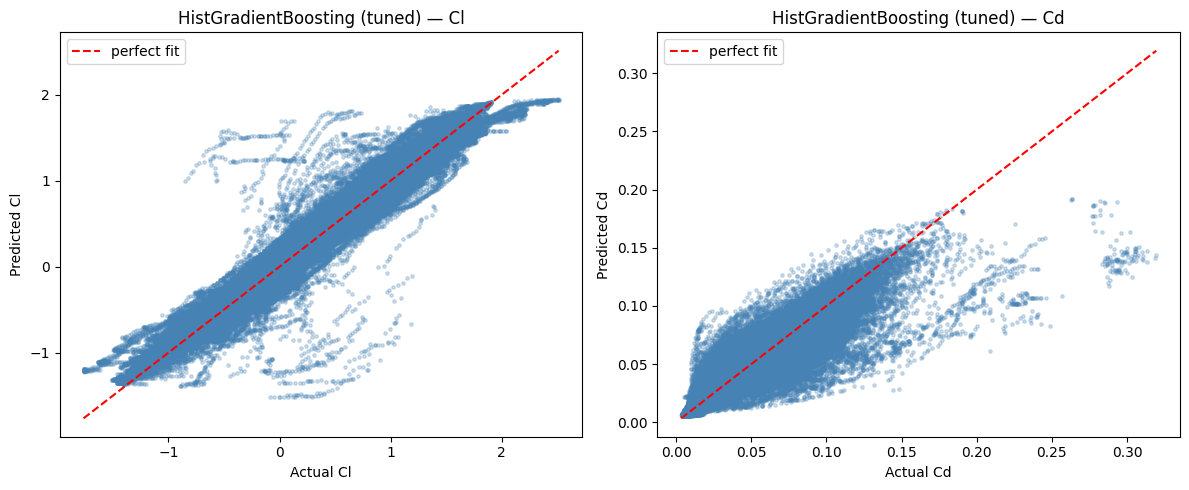

In [23]:
histgb_tuned = {}
for target, study in [("Cl", study_cl_hgb), ("Cd", study_cd_hgb)]:
    params = {**study.best_params, "random_state": 42, "early_stopping": False}
    model = HistGradientBoostingRegressor(**params)
    model.fit(X_train, y_train[target])
    histgb_tuned[target] = model

histgb_tuned_model = PerTargetRegressor(histgb_tuned)
histgb_tuned_pred = evaluate_and_store("HistGradientBoosting (tuned)", histgb_tuned_model, X_test, y_test)
plot_pred_vs_actual(y_test, histgb_tuned_pred, "HistGradientBoosting (tuned)")


**📘 Note — a subtle asymmetry worth one sentence in the report's methodology section:** look closely at how much data each "tuned, final" model actually trains on:

| Model | Trained on |
|---|---|
| LightGBM (tuned) | `X_train.iloc[fit_idx]` — **90%** of the training airfoils (10% held out for early stopping) |
| XGBoost (tuned) | `X_train.iloc[fit_idx]` — **90%** of the training airfoils (same reason) |
| HistGradientBoosting (tuned) | `X_train` — **100%** of the training airfoils (`early_stopping=False`, `max_iter` already fixed by tuning) |
| RandomForest (tuned) | `X_train` — **100%** of the training airfoils (no early stopping applies to RF at all) |

Not a bug — LightGBM/XGBoost genuinely need a validation slice to know when to stop boosting, while HistGB/RF don't — but it does mean the final head-to-head in Table 5 isn't training every model on identically-sized data. Worth a one-line disclosure if the report leans on small R² differences between rows (e.g. the RF-vs-XGBoost `Cl` result noted after cell 54, below).

**Random Forest (tuned)**

    Cl   MAE=0.086253  RMSE=0.138753  R²=0.966428
    Cd   MAE=0.007156  RMSE=0.014231  R²=0.792296


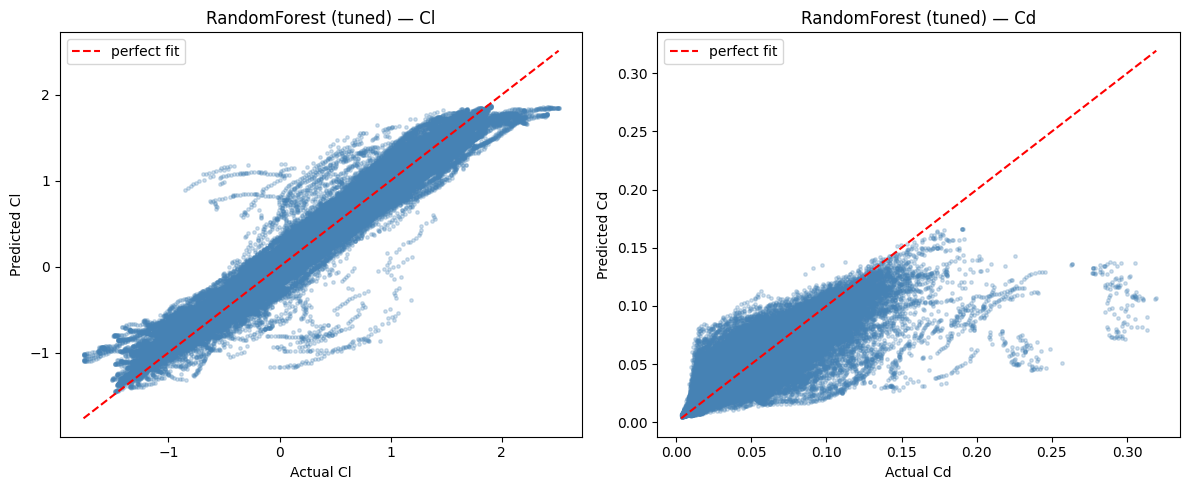

In [24]:
rf_tuned_model = RandomForestRegressor(**rf_search.best_params_, random_state=42, n_jobs=-1)
rf_tuned_model.fit(X_train, y_train)

rf_tuned_pred = evaluate_and_store("RandomForest (tuned)", rf_tuned_model, X_test, y_test)
plot_pred_vs_actual(y_test, rf_tuned_pred, "RandomForest (tuned)")


**Full comparison — baseline vs tuned**

In [25]:
results_df = print_comparison_table(
    results,
    model_order=[
        "RandomForest", "HistGradientBoosting", "LightGBM", "XGBoost",
        "RandomForest (tuned)", "HistGradientBoosting (tuned)", "LightGBM (tuned)", "XGBoost (tuned)",
    ],
)


| Model | Cl MAE ↓ | Cl RMSE ↓ | Cl R2 ↑ | Cd MAE ↓ | Cd RMSE ↓ | Cd R2 ↑ |
| --- | :---: | :---: | :---: | :---: | :---: | :---: |
| RandomForest | 0.095162 | 0.161001 | 0.954799 | 0.007447 | 0.015063 | 0.767295 |
| HistGradientBoosting | 0.092520 | 0.150998 | 0.960241 | 0.007517 | 0.013398 | 0.815911 |
| LightGBM | 0.092031 | 0.153987 | 0.958651 | 0.007006 | **0.012425** | **0.841668** |
| XGBoost | 0.091006 | 0.145210 | 0.963231 | 0.007449 | 0.013402 | 0.815797 |
| RandomForest (tuned) | **0.086253** | **0.138753** | **0.966428** | 0.007156 | 0.014231 | 0.792296 |
| HistGradientBoosting (tuned) | 0.089093 | 0.149257 | 0.961153 | 0.006926 | 0.012881 | 0.829829 |
| LightGBM (tuned) | 0.089825 | 0.149236 | 0.961163 | **0.006887** | 0.012685 | 0.834978 |
| XGBoost (tuned) | 0.090344 | 0.142695 | 0.964493 | 0.007009 | 0.013127 | 0.823260 |

**📊 Report table — Table 5: final tuned model comparison** (untouched test set — the honest, final number; reproduced from this cell's own rendered output)

| Model | Cl MAE ↓ | Cl RMSE ↓ | Cl R² ↑ | Cd MAE ↓ | Cd RMSE ↓ | Cd R² ↑ |
|---|---:|---:|---:|---:|---:|---:|
| RandomForest (tuned) | **0.086253** | **0.138753** | **0.966428** | 0.007156 | 0.014231 | 0.792296 |
| HistGradientBoosting (tuned) | 0.089093 | 0.149257 | 0.961153 | 0.006926 | 0.012881 | 0.829829 |
| LightGBM (tuned) | 0.089825 | 0.149236 | 0.961163 | **0.006887** | **0.012685** | **0.834978** |
| XGBoost (tuned) | 0.090344 | 0.142695 | 0.964493 | 0.007009 | 0.013127 | 0.823260 |

**📘 Non-cosmetic finding worth a decision (not just cleanup):** on this table, **RandomForest (tuned) actually has the best `Cl` R² (0.966428)** — narrowly ahead of XGBoost (tuned) at 0.964493. Yet `predict_aero()` (cell 58 below) hardcodes **XGBoost** for `Cl`. It's not *wrong* — the two are close, and the note after cell 50 above shows their tuning/training procedures weren't perfectly apples-to-apples — but as written it reads as an unintentional mismatch between "the table says X" and "the code uses Y." Either point `predict_aero()` at the RF model, or add one sentence explaining why XGBoost was kept anyway (inference speed, consistency with the earlier exploratory work, etc.) — either is fine, it just needs to be a stated choice rather than a silent one.

`LightGBM (tuned)` wins `Cd` (R² 0.834978) and is what `predict_aero()` uses for `Cd` — that part is consistent with this table.

**Save the tuned models**

In [26]:
joblib.dump(trained_models["LightGBM (tuned)"], "lightgbm_tuned.joblib")
joblib.dump(trained_models["XGBoost (tuned)"], "xgboost_tuned.joblib")
joblib.dump(trained_models["HistGradientBoosting (tuned)"], "histgb_tuned.joblib")
joblib.dump(trained_models["RandomForest (tuned)"], "randomforest_tuned.joblib")
print("Saved 4 tuned models.")


Saved 4 tuned models.


**⚠️ Duplicate/cleanup note — model save/load path mismatch (cell 56 vs cells 92–93):**

This cell saves to the current working directory with a bare filename:
```python
joblib.dump(trained_models["LightGBM (tuned)"], "lightgbm_tuned.joblib")
joblib.dump(trained_models["XGBoost (tuned)"], "xgboost_tuned.joblib")
```
but cell 92 (much further down) loads from a `models\` subfolder instead:
```python
final_cl_model = joblib.load("models\\xgboost_tuned.joblib")
final_cd_model = joblib.load("models\\lightgbm_tuned.joblib")
```
Unless the two `.joblib` files were manually moved into a `models/` folder between running these cells, a fresh top-to-bottom run will fail with `FileNotFoundError` at cell 92. **Not a code-logic issue this pass fixes** — just flagging it here, at the exact cell where it originates, so it's easy to correct later: either save to `"models/xgboost_tuned.joblib"` here, or load the bare filename down at cell 92 — whichever you pick, using `/` instead of `\\` keeps the notebook portable off Windows too.

# Separate tuned models are used per target: XGBoost (tuned) for Cl, LightGBM (tuned) for Cd. Cl is predicted with high accuracy (R² ≈ 0.96); Cd is harder to predict — especially near stall — and this limitation is documented in §11 rather than the model being dropped from the pipeline.

## 14. System overview — from trained models to a flight-ready controller

Cells 58 onward turn the four saved models into something that answers a real question: *"at what angle of attack does this airfoil hit a target drag coefficient, without stalling out the lift?"* This half of the notebook had no section headers before this pass — `## 14`–`## 19` below pick up the numbering where §13 left off.

### 🧭 System architecture

```text
┌────────────────────┐  ┌───────────┐  ┌───────┐  ┌─────────────────────┐
│ Airfoil geometry    │  │ Reynolds  │  │ Ncrit │  │ Angle of attack α    │
│ (4 shape params)    │  │ number Re │  │       │  │                      │
└──────────┬──────────┘  └─────┬─────┘  └───┬───┘  └───────────┬──────────┘
           │                   │            │                  │
           └─────────────┬─────┴─────┬──────┴──────────┬───────┘
                          ▼           ▼                 ▼
                 ┌────────────────────────────────────────────┐
                 │  Feature vector X = [t_max, x_t, c_max,     │
                 │       x_c, log10(Re), α, Ncrit]             │
                 └─────────────────────┬────────────────────────┘
                                       ▼
                       ┌───────────────────────────────┐
                       │   ML aerodynamic surrogate      │
                       │   XGBoost (tuned)  → Cl         │
                       │   LightGBM (tuned) → Cd         │
                       │        predict_aero()           │
                       └───────────┬─────────┬───────────┘
                                   ▼         ▼
                            predicted Cl   predicted Cd
                                   │         │
                                   └────┬────┘
                                        ▼
                       ┌───────────────────────────────┐
                       │   Alpha optimizer / controller   │
                       │   target Cd + minimum Cl (cl_min)│
                       │      robust_cd_controller()      │
                       └───────────────┬───────────────────┘
                                       ▼
                              Recommended α*, Cl, Cd
                                       │
                          ┌────────────┴────────────┐
                          ▼                          ▼
                XFOIL validation              Dashboard / future work
             (nearest-alpha lookup)              (not yet built)
```

### 🧭 The three controller generations

You iterated on the controller three times while building it, and **all three iterations are still present in the notebook**, side by side, instead of the last one replacing the earlier ones. That's the root cause behind most of the duplicate/cleanup notes from here to the end — it's normal notebook-driven-development residue, not sloppiness, and it's worth labeling explicitly so a reader doesn't have to reverse-engineer which version is "the real one" the way this review had to:

| Generation | Function | Constraint | Search method | Actually exercised by |
|---|---|---|---|---|
| v1 | `optimize_alpha` (cell 60) | none — maximizes Cl/Cd | continuous (`minimize_scalar`) | cells 61–63 only |
| v2 | `optimize_alpha_for_target_cd` → `aero_controller` (cells 64 / 74 / 80) | optional `cl_min` | continuous (`minimize_scalar`) | cells 65–87 |
| **v3 (final)** | `robust_cd_controller` (cell 88) | `cl_min` + explicit feasibility check | grid search (300 candidates) | cells 89, **95–96 (the notebook's own final sanity check)** |

Since v3 is the version the notebook's *own* last two cells (95–96) actually exercise, it's the de-facto final controller — worth saying so explicitly rather than leaving a reader to figure out which of the three is current.

```text
v1  optimize_alpha              maximize  Cl/Cd                    (no constraint)
        │ superseded by
        ▼
v2  optimize_alpha_for_target_cd /   minimize |Cd − Cd_target|     s.t. Cl ≥ cl_min
    aero_controller                  (continuous search)
        │ superseded by
        ▼
v3  robust_cd_controller          minimize |Cd − Cd_target|        s.t. Cl ≥ cl_min
    ← final, used in cells 89 & 95–96   (grid search, 300 pts, reports feasibility)
```

### 🧮 Formulations

**ML prediction (the surrogate model):**
$$
\boxed{(\text{airfoil geometry},\,Re,\,Ncrit,\,\alpha)\ \longrightarrow\ (Cl,\,Cd)}
$$

**Controller v1 — aerodynamic efficiency maximization:**
$$
\alpha^{*} = \arg\max_{\alpha}\ \frac{Cl_{pred}(\alpha)}{Cd_{pred}(\alpha)}
$$
`minimize_scalar` only *minimizes*, so the code returns $-\,Cl/Cd$ and minimizes that instead — same optimum, flipped sign (see `objective_alpha`, cell 59).

**Controller v2/v3 — target-drag optimization (the project's actual control idea):**
$$
\boxed{\alpha^{*}=\arg\min_{\alpha}\ \big|\,Cd_{pred}(\alpha)-Cd_{target}\,\big|}
\qquad\text{subject to}\qquad
\boxed{Cl_{pred}(\alpha)\ge Cl_{min}}
$$

The ML model predicts aerodynamic behavior; the optimizer separately chooses the angle of attack. That separation is a good design choice — a different or better surrogate model could be dropped in later without touching any optimization logic.

In [38]:
def predict_aero(alpha, airfoil_features, re_value, ncrit_value):
    input_data = pd.DataFrame([{
        "max_thickness_percent": airfoil_features["max_thickness_percent"],
        "max_thickness_position": airfoil_features["max_thickness_position"],
        "max_camber_percent": airfoil_features["max_camber_percent"],
        "max_camber_position": airfoil_features["max_camber_position"],
        "log_Re": np.log10(re_value),
        "alpha": alpha,
        "Ncrit": ncrit_value
    }])

    # Select the target-specific models and extract scalar predictions.
    cl = float(xgb_tuned["Cl"].predict(input_data)[0])
    cd = float(lgb_tuned["Cd"].predict(input_data)[0])

    return cl, cd


### 15. `predict_aero()` — bridging the ML models and the optimizer

This is the one function every controller version below calls. It builds a single-row feature `DataFrame` matching the exact column layout of `FEATURES` (§4), converts `re_value` to `log10(Re)` to match training, and returns a plain `(cl, cd)` tuple. Everything downstream — all three controller generations — only ever talks to the models through this function.

In [39]:
def objective_alpha(alpha, airfoil_features, re_value, ncrit_value):
    cl, cd = predict_aero(
        alpha,
        airfoil_features,
        re_value,
        ncrit_value
    )
    
    return -(cl / cd)

In [40]:
def optimize_alpha(airfoil_features, re_value, ncrit_value):
    
    result = minimize_scalar(
        objective_alpha,
        bounds=(-10, 15),
        method="bounded",
        args=(
            airfoil_features,
            re_value,
            ncrit_value
        )
    )
    
    best_alpha = float(result.x)

    cl, cd = predict_aero(
        best_alpha,
        airfoil_features,
        re_value,
        ncrit_value
    )

    cl = float(cl)
    cd = float(cd)

    return {
        "optimal_alpha": best_alpha,
        "predicted_Cl": cl,
        "predicted_Cd": cd,
        "predicted_Cl_Cd": cl / cd
    }

#### 15.1 Controller v1 — unconstrained efficiency maximization (`optimize_alpha`)

Searches `alpha ∈ [-10°, 15°]` with `minimize_scalar(method="bounded")` for the angle that maximizes `Cl/Cd` (formula in §14 above). No drag target, no lift floor — just "find the single most efficient angle." Superseded by v2 below the moment the project's actual goal (hit a *target* drag, not just the most efficient one) is introduced.

In [41]:
airfoil_features = {
    "max_thickness_percent": 12.0,
    "max_thickness_position": 0.30,
    "max_camber_percent": 2.0,
    "max_camber_position": 0.40
}

result = optimize_alpha(
    airfoil_features,
    re_value=500000,
    ncrit_value=9
)

result

{'optimal_alpha': 4.512169593284247,
 'predicted_Cl': 0.7333778738975525,
 'predicted_Cd': 0.008603755718864086,
 'predicted_Cl_Cd': 85.23927199485587}

**📘 Note:** first demo, run on a **hand-typed synthetic airfoil** (`max_thickness_percent=12.0`, etc. — not pulled from the real dataset). Result from this cell's own output: optimal α ≈ **4.51°**, predicted Cl ≈ 0.733, predicted Cd ≈ 0.0086, Cl/Cd ≈ **85.2**. Useful as an early plumbing check before switching to real dataset airfoils at cell 66.

In [42]:
alphas = np.linspace(-10, 15, 200)

cl_values = []
cd_values = []
efficiency_values = []

for alpha in alphas:
    cl, cd = predict_aero(
        alpha,
        airfoil_features,
        re_value=500000,
        ncrit_value=9
    )

    cl_values.append(cl)
    cd_values.append(cd)
    efficiency_values.append(cl / cd)

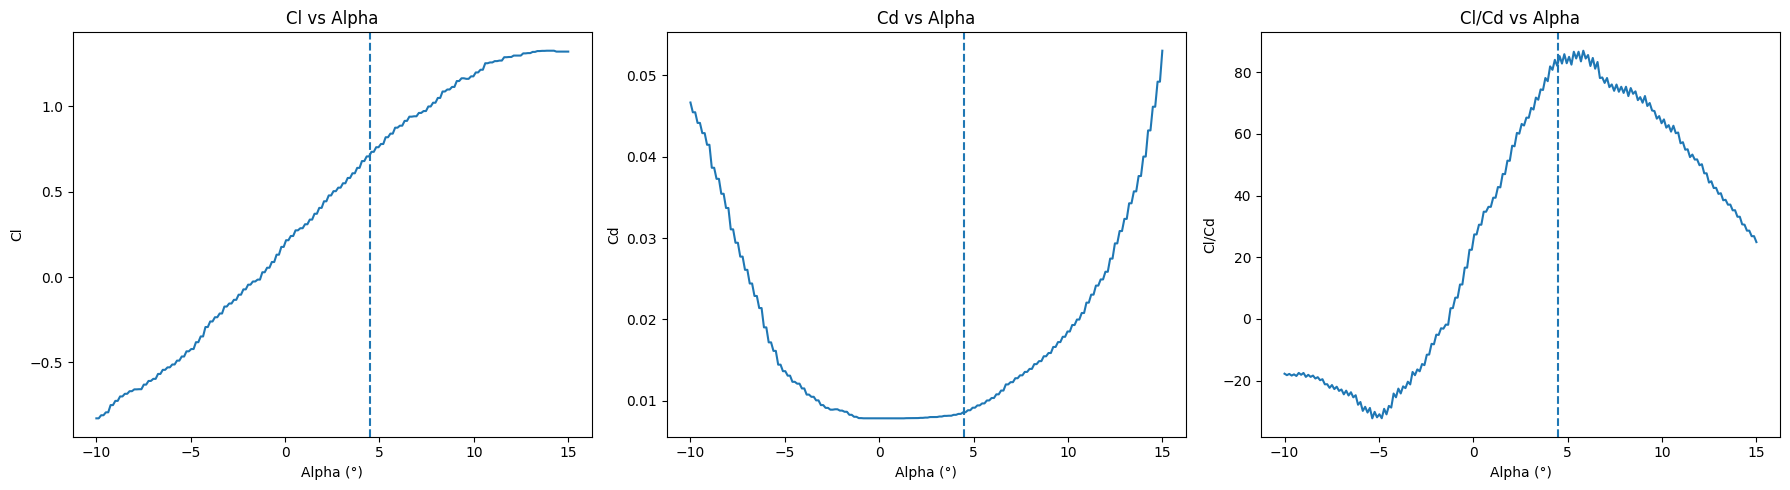

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(alphas, cl_values)
axes[0].axvline(result["optimal_alpha"], linestyle="--")
axes[0].set_title("Cl vs Alpha")
axes[0].set_xlabel("Alpha (°)")
axes[0].set_ylabel("Cl")

axes[1].plot(alphas, cd_values)
axes[1].axvline(result["optimal_alpha"], linestyle="--")
axes[1].set_title("Cd vs Alpha")
axes[1].set_xlabel("Alpha (°)")
axes[1].set_ylabel("Cd")

axes[2].plot(alphas, efficiency_values)
axes[2].axvline(result["optimal_alpha"], linestyle="--")
axes[2].set_title("Cl/Cd vs Alpha")
axes[2].set_xlabel("Alpha (°)")
axes[2].set_ylabel("Cl/Cd")

plt.tight_layout()
plt.show()

**📘 Note — report plot candidate:** this 3-panel (Cl vs α / Cd vs α / Cl÷Cd vs α) layout reappears almost identically at cells 90–91, later in the notebook, using the *v3* controller's optimum instead of v1's. Not a bug — it's the same visualization block reused for two different controller generations, which actually makes a nice "before/after" pair for the report (see the plot checklist, §21, near the end). As **code** it is the same block twice though; if you clean this notebook up, a single `plot_alpha_sweep(airfoil_features, re_value, ncrit_value, marker_alpha=None, marker_cd_target=None)` helper next to the other helpers in §7 would let you call it twice instead of maintaining two copies.

In [44]:
def optimize_alpha_for_target_cd(
    airfoil_features,
    re_value,
    ncrit_value,
    target_cd,
    alpha_min=-10,
    alpha_max=15
):
    def objective(alpha):
        _, cd = predict_aero(
            alpha,
            airfoil_features,
            re_value,
            ncrit_value
        )
        return abs(cd - target_cd)

    result = minimize_scalar(
        objective,
        bounds=(alpha_min, alpha_max),
        method="bounded"
    )

    best_alpha = result.x

    cl, cd = predict_aero(
        best_alpha,
        airfoil_features,
        re_value,
        ncrit_value
    )

    return {
        "target_Cd": target_cd,
        "optimal_alpha": best_alpha,
        "predicted_Cl": cl,
        "predicted_Cd": cd,
        "error": abs(cd - target_cd)
    }

**⚠️ Duplicate/cleanup note #2 — `optimize_alpha_for_target_cd()` is defined twice (this cell = v1, and again at cell 74 = v2):**

- **This version (v1):** no `cl_min` parameter; returns a dict with key **`"error"`**.
- **Cell 74's version (v2):** adds `cl_min=0.0`; returns a dict with key **`"Cd_error"`** instead — a rename, not just an addition.
- The key rename matters if you ever build a combined `DataFrame` from calls made against both versions — the columns won't line up.
- **Recommendation:** keep only the cell-74 version — it's a strict superset (`cl_min=0.0` exactly reproduces this version's unconstrained behavior).

#### 15.2 Controller v2 — target-drag optimization (`optimize_alpha_for_target_cd`)

This is the project's actual control idea, introduced here in its first (unconstrained) form: instead of maximizing efficiency, search for the angle whose *predicted* `Cd` is closest to a user-chosen `target_cd`. Formula in §14 above.

In [45]:
target_result = optimize_alpha_for_target_cd(
    airfoil_features,
    re_value=500000,
    ncrit_value=9,
    target_cd=0.010
)

target_result

{'target_Cd': 0.01,
 'optimal_alpha': np.float64(5.683675137384126),
 'predicted_Cl': 0.8399539589881897,
 'predicted_Cd': 0.010057462554860317,
 'error': 5.746255486031686e-05}

**📘 Note:** still on the **synthetic airfoil** from cell 61 at this point (`airfoil_features` hasn't been overwritten with real data yet) — result: optimal α ≈ 5.68°, predicted Cd ≈ 0.01006, essentially exact (`error` ≈ 5.7e-05) for `target_cd=0.010`. The real-dataset version of this same call comes two cells later, after cell 66 switches `airfoil_features` to airfoil 0's actual geometry.

In [46]:
test_airfoil_id = 0
test_re = 500000
test_ncrit = 9

airfoil_row = df[df["airfoil_id"] == test_airfoil_id].iloc[0]

airfoil_features = {
    "max_thickness_percent": airfoil_row["max_thickness_percent"],
    "max_thickness_position": airfoil_row["max_thickness_position"],
    "max_camber_percent": airfoil_row["max_camber_percent"],
    "max_camber_position": airfoil_row["max_camber_position"]
}

airfoil_features

{'max_thickness_percent': np.float64(7.997989578885102),
 'max_thickness_position': np.float64(0.1809045226130653),
 'max_camber_percent': np.float64(7.0023998671105385),
 'max_camber_position': np.float64(0.3517587939698492)}

**📘 Note:** from here on, `airfoil_features` holds **airfoil 0's real geometry** pulled straight out of `df`, replacing the hand-typed synthetic values used in cells 61–65. This exact lookup (same 4-key dict, same `airfoil_id == 0`) gets rebuilt identically again at cell 76 — see the duplicate note there.

In [47]:
target_cd = 0.010

result = optimize_alpha_for_target_cd(
    airfoil_features,
    re_value=test_re,
    ncrit_value=test_ncrit,
    target_cd=target_cd
)

result

{'target_Cd': 0.01,
 'optimal_alpha': np.float64(0.6316603296427543),
 'predicted_Cl': 0.71965491771698,
 'predicted_Cd': 0.01212067245963529,
 'error': 0.0021206724596352904}

In [48]:
actual_data = df[
    (df["airfoil_id"] == test_airfoil_id) &
    (df["Re"] == test_re) &
    (df["Ncrit"] == test_ncrit)
].copy()

optimal_alpha = result["optimal_alpha"]

actual_data["alpha_error"] = (
    actual_data["alpha"] - optimal_alpha
).abs()

closest_row = actual_data.loc[
    actual_data["alpha_error"].idxmin()
]

print("Optimal ML alpha:", optimal_alpha)
print("Nearest XFOIL alpha:", closest_row["alpha"])
print("ML predicted Cd:", result["predicted_Cd"])
print("XFOIL actual Cd:", closest_row["Cd"])
print("Target Cd:", target_cd)

Optimal ML alpha: 0.6316603296427543
Nearest XFOIL alpha: 0.5
ML predicted Cd: 0.01212067245963529
XFOIL actual Cd: 0.01071
Target Cd: 0.01


In [49]:
real_error = abs(result["predicted_Cd"] - closest_row["Cd"])
print("Real Cd error:", real_error)

Real Cd error: 0.0014106724596352899


In [50]:
alpha_difference = abs(
    result["optimal_alpha"] - closest_row["alpha"]
)

print("Alpha difference:", alpha_difference)

Alpha difference: 0.13166032964275431


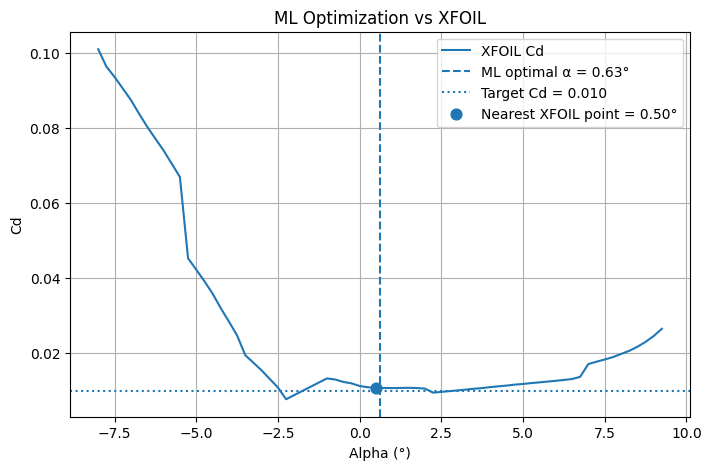

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    actual_data["alpha"],
    actual_data["Cd"],
    label="XFOIL Cd"
)

plt.axvline(
    result["optimal_alpha"],
    linestyle="--",
    label=f"ML optimal α = {result['optimal_alpha']:.2f}°"
)

plt.axhline(
    target_cd,
    linestyle=":",
    label=f"Target Cd = {target_cd:.3f}"
)

plt.scatter(
    closest_row["alpha"],
    closest_row["Cd"],
    s=60,
    label=f"Nearest XFOIL point = {closest_row['alpha']:.2f}°"
)

plt.xlabel("Alpha (°)")
plt.ylabel("Cd")
plt.title("ML Optimization vs XFOIL")
plt.legend()
plt.grid(True)

plt.show()

**📘 Note — report plot candidate ("ML vs XFOIL", single airfoil):** this figure directly compares the ML controller's recommendation against the nearest real XFOIL data point. Numbers from the cells above: ML optimal α ≈ **0.632°** vs nearest XFOIL α = **0.50°** (alpha difference ≈ 0.132°); ML predicted Cd ≈ **0.01212** vs XFOIL actual Cd = **0.01071** (real Cd error ≈ 0.00141) against a target of 0.010. Good candidate for the "XFOIL validation" section of a report (it's effectively a single-airfoil preview of the 5-airfoil Table 6 further down, after cell 87).

In [52]:
target_cds = [0.008, 0.010, 0.012, 0.015, 0.020]

results = []

for target in target_cds:
    r = optimize_alpha_for_target_cd(
        airfoil_features,
        re_value=500000,
        ncrit_value=9,
        target_cd=target
    )

    results.append(r)

target_results = pd.DataFrame(results)

target_results

,target_Cd,optimal_alpha,predicted_Cl,predicted_Cd,error
0,0.008,0.631660,0.719655,0.012121,0.004121
1,0.010,0.631660,0.719655,0.012121,0.002121
2,0.012,0.631660,0.719655,0.012121,0.000121
3,0.015,6.429858,1.303479,0.014804,0.000196
4,0.020,9.053492,1.554826,0.019763,0.000237


**⚠️ Duplicate/cleanup note — global variable name collision: `results` (this cell) vs `results` (cell 15):**

```python
results = []          # ← this line
for target in target_cds:
    r = optimize_alpha_for_target_cd(...)
    results.append(r)
```

`results` was originally a **dict** created back in §7 (cell 15) that every `evaluate_and_store()` call in §8/§13 writes model-comparison metrics into, and that `print_comparison_table()` reads from. This cell reassigns the same global name to a plain **list**, for a completely unrelated purpose (collecting rows of a target-Cd sweep for a `DataFrame`).

In this notebook's current top-to-bottom order this happens to be harmless — nothing after this point calls `print_comparison_table(results, ...)` or `evaluate_and_store(...)` again. But it's a landmine for future edits: if you ever add a new model and try to score it after this cell has run, `results[(name, target)] = {...}` will raise a `TypeError` (list indices must be integers), and the error message won't obviously point back to this line. Worth renaming this local variable to something like `sweep_results` if you keep working in this notebook.

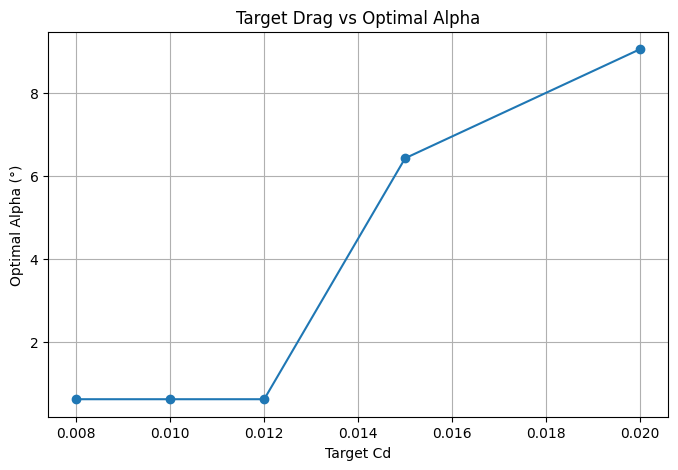

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    target_results["target_Cd"],
    target_results["optimal_alpha"],
    marker="o"
)

plt.xlabel("Target Cd")
plt.ylabel("Optimal Alpha (°)")
plt.title("Target Drag vs Optimal Alpha")
plt.grid(True)

plt.show()

**📊 Report table snapshot — target-Cd sweep** (5 target values, real airfoil 0, from this cell's own output)

| target_Cd | optimal_alpha | predicted_Cl | predicted_Cd | error |
|---:|---:|---:|---:|---:|
| 0.008 | 0.6317° | 0.7197 | 0.01212 | 0.00412 |
| 0.010 | 0.6317° | 0.7197 | 0.01212 | 0.00212 |
| 0.012 | 0.6317° | 0.7197 | 0.01212 | 0.00012 |
| 0.015 | 6.4299° | 1.3035 | 0.01480 | 0.00020 |
| 0.020 | 9.0535° | 1.5548 | 0.01976 | 0.00024 |

**📘 Physical-insight note:** the first three rows (targets 0.008, 0.010, 0.012) all land on the **identical** angle, `Cl`, and `Cd`. That's not a bug — for this airfoil/Re/Ncrit combination, **0.01212 appears to be roughly the achievable minimum drag** in the searched α-range (−10° to 15°), so any target *below* that floor can't actually be reached — the optimizer just reports the closest achievable point every time, which happens to be the same point for all three low targets. Worth a sentence in the report: this is a second, independent piece of evidence (alongside the §11 ablation) that this model's `Cd` surface has flat, plateau-like regions rather than a smooth response everywhere — see also the v2-vs-v3 comparison noted at cell 89, further down, which finds the same kind of flat spot again.

In [54]:
def optimize_alpha_for_target_cd(
    airfoil_features,
    re_value,
    ncrit_value,
    target_cd,
    cl_min=0.0,
    alpha_min=-10,
    alpha_max=15
):
    def objective(alpha):
        cl, cd = predict_aero(
            alpha,
            airfoil_features,
            re_value,
            ncrit_value
        )

        if cl < cl_min:
            return 1000 + abs(cl - cl_min)

        return abs(cd - target_cd)

    result = minimize_scalar(
        objective,
        bounds=(alpha_min, alpha_max),
        method="bounded"
    )

    best_alpha = result.x

    cl, cd = predict_aero(
        best_alpha,
        airfoil_features,
        re_value,
        ncrit_value
    )

    return {
        "target_Cd": target_cd,
        "optimal_alpha": best_alpha,
        "predicted_Cl": cl,
        "predicted_Cd": cd,
        "Cd_error": abs(cd - target_cd)
    }

**📘 Note:** this is the version (`cl_min` default `0.0`, dict key `Cd_error`) that every controller call from here to the end of the notebook actually resolves to, once this cell has run — the earlier definition at cell 64 is no longer reachable. See the duplicate note at cell 64 for the recommended cleanup.

In [55]:
result = optimize_alpha_for_target_cd(
    airfoil_features,
    re_value=500000,
    ncrit_value=9,
    target_cd=0.010,
    cl_min=0.5
)

result

{'target_Cd': 0.01,
 'optimal_alpha': np.float64(0.6515534634917386),
 'predicted_Cl': 0.71965491771698,
 'predicted_Cd': 0.01212067245963529,
 'Cd_error': 0.0021206724596352904}

In [56]:
test_airfoil_id = 0
test_re = 500000
test_ncrit = 9

row = df[df["airfoil_id"] == test_airfoil_id].iloc[0]

airfoil_features = {
    "max_thickness_percent": row["max_thickness_percent"],
    "max_thickness_position": row["max_thickness_position"],
    "max_camber_percent": row["max_camber_percent"],
    "max_camber_position": row["max_camber_position"]
}

**⚠️ Duplicate/cleanup note #3:** this cell rebuilds `airfoil_features` for `airfoil_id == 0` — the exact same 4-key lookup already done at cell 66, with identical values (same row, same columns). Nothing changes as a result of running this cell again. **Recommendation:** delete this cell; cell 66's dictionary is still valid and unchanged at this point in the notebook.

In [57]:
final_result = optimize_alpha_for_target_cd(
    airfoil_features,
    re_value=test_re,
    ncrit_value=test_ncrit,
    target_cd=0.010,
    cl_min=0.5
)

final_result

{'target_Cd': 0.01,
 'optimal_alpha': np.float64(0.6515534634917386),
 'predicted_Cl': 0.71965491771698,
 'predicted_Cd': 0.01212067245963529,
 'Cd_error': 0.0021206724596352904}

**⚠️ Duplicate/cleanup note #4 — redundant repeat demo calls:** cells **75**, **77**, and **81** (below) all call essentially the same wrapped optimizer — same airfoil (id 0), same `target_cd=0.010`, same `cl_min=0.5` — and all three return **bit-for-bit identical** numbers (`optimal_alpha ≈ 0.6516°`, `predicted_Cd ≈ 0.01212`, etc.). This is a direct consequence of duplicate notes #2/#3 above: every time the surrounding code got re-verified after a redefinition, the old verification cell stayed in the notebook rather than being replaced. **Recommendation:** keep one demo call per controller generation and delete the rest.

(Note: cell **65**, earlier, used the *synthetic* airfoil rather than airfoil 0, and cell **67** used airfoil 0 but against the *v1* function — neither of those is part of this "identical trio," they're genuinely earlier/different demos kept for context.)

In [58]:
optimized_alpha = final_result["optimal_alpha"]

print(f"Optimized Alpha: {optimized_alpha:.2f}°")

Optimized Alpha: 0.65°


In [59]:
alpha_control = optimized_alpha

**⚠️ Duplicate/cleanup note — dead variable:**
```python
alpha_control = optimized_alpha
```
Assigned once here, never read again anywhere else in the notebook. Harmless, but it's a leftover from an earlier draft of the controller wiring — safe to delete.

#### 15.3 Thin wrapper — `aero_controller()`

In [60]:
def aero_controller(
    airfoil_features,
    re_value,
    ncrit_value,
    target_cd,
    cl_min=0.5
):
    result = optimize_alpha_for_target_cd(
        airfoil_features=airfoil_features,
        re_value=re_value,
        ncrit_value=ncrit_value,
        target_cd=target_cd,
        cl_min=cl_min
    )

    return result

**📘 Note:** `aero_controller()` (just defined above) is a thin pass-through wrapper around `optimize_alpha_for_target_cd()` (v2) — it doesn't add new logic, just a slightly friendlier name/signature for the multi-airfoil loop that follows in §16.

In [61]:
controller_result = aero_controller(
    airfoil_features=airfoil_features,
    re_value=500000,
    ncrit_value=9,
    target_cd=0.010,
    cl_min=0.5
)

controller_result

{'target_Cd': 0.01,
 'optimal_alpha': np.float64(0.6515534634917386),
 'predicted_Cl': 0.71965491771698,
 'predicted_Cd': 0.01212067245963529,
 'Cd_error': 0.0021206724596352904}

**📘 Note:** confirms the redundant-demo pattern flagged after cell 77 — this call reproduces cells 75/77's numbers exactly (same airfoil, target, `cl_min`), since `aero_controller()` is just a wrapper around the same v2 function.

## 16. Multi-airfoil controller test

The next few cells run the v2 controller across **5 different real airfoils** (`airfoil_id` 0–4) at the same `target_cd=0.010`, `cl_min=0.5`, and Reynolds/Ncrit conditions, collecting the results into `controller_results` — a first look at whether the controller generalizes across shapes, not just the one airfoil used in every demo so far.

In [ ]:
test_airfoils = [0, 1, 2, 3, 4]
target_cd = 0.010
re_value = 500000
ncrit_value = 9

controller_results = []

for airfoil_id in test_airfoils:

    row = df[df["airfoil_id"] == airfoil_id].iloc[0]

    features = {
        "max_thickness_percent": row["max_thickness_percent"],
        "max_thickness_position": row["max_thickness_position"],
        "max_camber_percent": row["max_camber_percent"],
        "max_camber_position": row["max_camber_position"]
    }

    result = aero_controller(
        airfoil_features=features,
        re_value=re_value,
        ncrit_value=ncrit_value,
        target_cd=target_cd,
        cl_min=0.5
    )

    controller_results.append({
        "airfoil_id": airfoil_id,
        **result
    })

controller_results = pd.DataFrame(controller_results)

,airfoil_id,target_Cd,optimal_alpha,predicted_Cl,predicted_Cd,Cd_error
0,0,0.01,0.651553,0.719655,0.012121,0.002121
1,1,0.01,4.081983,1.004908,0.009609,0.000391
2,2,0.01,4.735545,0.531841,0.009759,0.000241
3,3,0.01,5.177807,0.680231,0.009842,0.000158
4,4,0.01,4.769331,0.698314,0.009689,0.000311


In [64]:
controller_results[
    ["airfoil_id",
     "target_Cd",
     "optimal_alpha",
     "predicted_Cl",
     "predicted_Cd",
     "Cd_error"]
]

,airfoil_id,target_Cd,optimal_alpha,predicted_Cl,predicted_Cd,Cd_error
0,0,0.01,0.651553,0.719655,0.012121,0.002121
1,1,0.01,4.081983,1.004908,0.009609,0.000391
2,2,0.01,4.735545,0.531841,0.009759,0.000241
3,3,0.01,5.177807,0.680231,0.009842,0.000158
4,4,0.01,4.769331,0.698314,0.009689,0.000311


**⚠️ Duplicate/cleanup note — `controller_results` displayed three times in a row (cells 82, 83, 84):**

- Cell 82 computes `controller_results` and displays it (its last line).
- Cell 83 is a bare `controller_results` — identical output, nothing new.
- Cell 84 re-selects the same 6 columns the DataFrame already has, in the same order — a no-op that produces the same table a third time.

**Recommendation:** keep only cell 82's output (or, if you like having an explicit "here's the final table" cell, keep 84's column-selection version instead of the raw one — but not both 83 *and* 84).

## 17. XFOIL round-trip validation (5 airfoils)

For each of the 5 controller results above, the next cell finds the **nearest real XFOIL data row** (by absolute `alpha` difference, at the same `Re`/`Ncrit`) for that airfoil, and compares the ML-recommended angle and predicted `Cd` against that real, independently-computed value. This is the strongest evidence in the notebook that the pipeline works end-to-end — it isn't just reporting a held-out R², it's checking the *actual controller output* against an independent aerodynamics tool.

In [65]:
validation_results = []

for _, row in controller_results.iterrows():

    airfoil_id = int(row["airfoil_id"])
    optimal_alpha = row["optimal_alpha"]

    actual = df[
        (df["airfoil_id"] == airfoil_id) &
        (df["Re"] == re_value) &
        (df["Ncrit"] == ncrit_value)
    ].copy()

    if actual.empty:
        continue

    actual["alpha_diff"] = (
        actual["alpha"] - optimal_alpha
    ).abs()

    nearest = actual.loc[actual["alpha_diff"].idxmin()]

    validation_results.append({
        "airfoil_id": airfoil_id,
        "ML_alpha": optimal_alpha,
        "XFOIL_alpha": nearest["alpha"],
        "ML_Cd": row["predicted_Cd"],
        "XFOIL_Cd": nearest["Cd"],
        "Target_Cd": row["target_Cd"],
        "Cd_error": abs(row["predicted_Cd"] - nearest["Cd"])
    })

validation_results = pd.DataFrame(validation_results)

validation_results

,airfoil_id,ML_alpha,XFOIL_alpha,ML_Cd,XFOIL_Cd,Target_Cd,Cd_error
0,0,0.651553,0.50,0.012121,0.01071,0.01,0.001411
1,1,4.081983,4.00,0.009609,0.01138,0.01,0.001771
2,2,4.735545,4.75,0.009759,0.01056,0.01,0.000801
3,3,5.177807,5.00,0.009842,0.00951,0.01,0.000332
4,4,4.769331,4.75,0.009689,0.00933,0.01,0.000359


In [67]:
print("Mean Cd Error:",
      validation_results["Cd_error"].mean())

print("Mean Alpha Difference:",
      validation_results["ML_alpha"]
      .sub(validation_results["XFOIL_alpha"])
      .abs()
      .mean())

Mean Cd Error: 0.000934682508443803
Mean Alpha Difference: 0.08902570546717774


**📊 Report table — Table 6: 5-airfoil controller validation against XFOIL** (from cells 85/87's own output)

| airfoil_id | ML α | XFOIL α (nearest) | ML Cd | XFOIL Cd | Target Cd | Cd error |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.652° | 0.50° | 0.01212 | 0.01071 | 0.010 | 0.00141 |
| 1 | 4.082° | 4.00° | 0.00961 | 0.01138 | 0.010 | 0.00177 |
| 2 | 4.736° | 4.75° | 0.00976 | 0.01056 | 0.010 | 0.00080 |
| 3 | 5.178° | 5.00° | 0.00984 | 0.00951 | 0.010 | 0.00033 |
| 4 | 4.769° | 4.75° | 0.00969 | 0.00933 | 0.010 | 0.00036 |

**Aggregate (this cell's own printout):** Mean Cd error ≈ **0.000935**; mean |α difference| ≈ **0.089°**. That's a tight round-trip agreement between the ML controller and an independent physics tool across 5 different airfoil shapes — a genuinely strong result worth leading with in a results section.

## 18. Controller v3 (final) — `robust_cd_controller()`

The next cell replaces v2's continuous `minimize_scalar` search with an explicit **grid search over 300 candidate angles**, filters to only the candidates where `predicted_Cl ≥ cl_min` (the *feasible* set), then picks whichever feasible candidate's `Cd` is closest to the target — and explicitly reports whether the target was actually reachable (`"Target reached"`) or only approximately so (`"Closest feasible solution"`). This is a more defensive design than v2: it can't silently return an infeasible answer, and it doesn't rely on `minimize_scalar` finding the right local optimum in one continuous pass.

In [68]:
def robust_cd_controller(
    airfoil_features,
    re_value,
    ncrit_value,
    target_cd,
    cl_min=0.5,
    alpha_min=-10,
    alpha_max=15,
    n_points=300
):
    alphas = np.linspace(alpha_min, alpha_max, n_points)

    predictions = []

    for alpha in alphas:
        cl, cd = predict_aero(
            alpha,
            airfoil_features,
            re_value,
            ncrit_value
        )

        if np.isfinite(cl) and np.isfinite(cd) and cd > 0:
            predictions.append((alpha, cl, cd))

    if not predictions:
        raise ValueError("No valid ML predictions found.")

    valid = [
        p for p in predictions
        if p[1] >= cl_min
    ]

    if not valid:
        return {
            "status": "No feasible alpha",
            "target_Cd": target_cd
        }

    best = min(
        valid,
        key=lambda p: abs(p[2] - target_cd)
    )

    alpha, cl, cd = best

    reachable = any(
        abs(p[2] - target_cd) < 1e-4
        for p in valid
    )

    return {
        "status": "Target reached" if reachable else "Closest feasible solution",
        "target_Cd": target_cd,
        "optimal_alpha": alpha,
        "predicted_Cl": cl,
        "predicted_Cd": cd,
        "Cd_error": abs(cd - target_cd),
        "Cl_Cd": cl / cd
    }

In [69]:
robust_result = robust_cd_controller(
    airfoil_features,
    re_value=500000,
    ncrit_value=9,
    target_cd=0.010,
    cl_min=0.5
)

robust_result

{'status': 'Closest feasible solution',
 'target_Cd': 0.01,
 'optimal_alpha': np.float64(0.03344481605351213),
 'predicted_Cl': 0.6498776078224182,
 'predicted_Cd': 0.01212067245963529,
 'Cd_error': 0.0021206724596352904,
 'Cl_Cd': 53.61728979862005}

**📘 Note — labeling the actual final controller, and a finding worth a sentence in the report:**

This is the version the notebook's own final two cells (95–96, at the very end) exercise — making `robust_cd_controller()` the de-facto final controller, ahead of v1 and v2 above.

Comparing **this v3 result** against the **v2 result** for the *exact same inputs* (airfoil 0, `target_cd=0.010`, `cl_min=0.5` — cells 75/77/81):

| | optimal α | predicted Cl | predicted Cd |
|---|---:|---:|---:|
| v2 (continuous search) | 0.6516° | 0.7197 | 0.01212 |
| v3 (grid search, 300 pts) | **0.0334°** | 0.6499 | **0.01212** |

Two different search methods land on two clearly different angles (0.65° vs 0.03°) but the **identical predicted Cd**. This lines up with everything else this notebook has already found about the model's `Cd` surface: the §11 ablation diagnosed piecewise-constant, leaf-based predictions; the cell-73 sweep found three different targets converging on one identical point; and now two different optimizers find two different angles that happen to score identically on `Cd`. Read together, these three observations tell one coherent story for the limitations section: **the `Cd` surface has flat, plateau-like regions in this α-window, so many different angles score equally well on drag alone** — which is exactly why the `cl_min` lift constraint matters here, since it's the tiebreaker that actually distinguishes between otherwise-equal candidates.

In [70]:
alphas = np.linspace(-10, 15, 300)

cl_values = []
cd_values = []
efficiency_values = []

for alpha in alphas:
    cl, cd = predict_aero(
        alpha,
        airfoil_features,
        re_value=500000,
        ncrit_value=9
    )

    cl_values.append(cl)
    cd_values.append(cd)
    efficiency_values.append(cl / cd)

optimal_alpha = robust_result["optimal_alpha"]

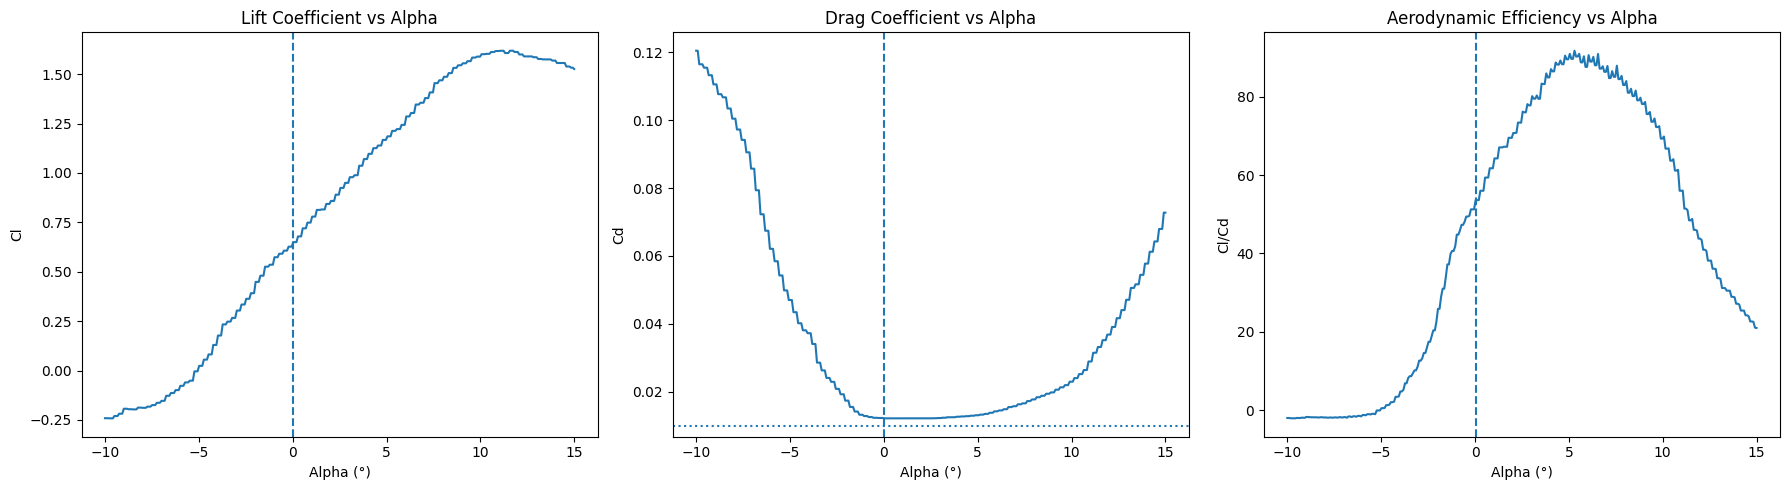

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(alphas, cl_values)
axes[0].axvline(optimal_alpha, linestyle="--")
axes[0].set_title("Lift Coefficient vs Alpha")
axes[0].set_xlabel("Alpha (°)")
axes[0].set_ylabel("Cl")

axes[1].plot(alphas, cd_values)
axes[1].axvline(optimal_alpha, linestyle="--")
axes[1].axhline(robust_result["target_Cd"], linestyle=":")
axes[1].set_title("Drag Coefficient vs Alpha")
axes[1].set_xlabel("Alpha (°)")
axes[1].set_ylabel("Cd")

axes[2].plot(alphas, efficiency_values)
axes[2].axvline(optimal_alpha, linestyle="--")
axes[2].set_title("Aerodynamic Efficiency vs Alpha")
axes[2].set_xlabel("Alpha (°)")
axes[2].set_ylabel("Cl/Cd")

plt.tight_layout()
plt.show()

**📘 Note:** final version of the 3-panel Cl/Cd/efficiency-vs-alpha plot, pairing with cells 62–63 (same layout, now marking the v3 controller's optimum with `n_points=300` instead of 200). If report space is tight, this pair (90–91) is the one to keep over 62–63, since it reflects the actual final controller rather than the superseded v1.

## 19. Save / reload verification

In [73]:
final_cl_model = joblib.load("models\\xgboost_tuned.joblib")
final_cd_model = joblib.load("models\\lightgbm_tuned.joblib")

In [76]:
import os

print(os.path.getsize("models\\xgboost_tuned.joblib"))
print(os.path.getsize("models\\lightgbm_tuned.joblib"))

10392884
9344324


**📘 Note:** file sizes (~10.4 MB for the XGBoost wrapper, ~9.3 MB for the LightGBM wrapper, per this cell's own printout) confirm real, non-trivial fitted models were loaded — a quick sanity check that the reload didn't silently pick up an empty or corrupted file. Reminder: this load only succeeds if the path bug flagged after cell 56 has been resolved (i.e., the files actually exist under a `models/` folder relative to the notebook).

In [84]:
def predict_aero(alpha, airfoil_features, re_value, ncrit_value):
    input_data = pd.DataFrame([{
        "max_thickness_percent": airfoil_features["max_thickness_percent"],
        "max_thickness_position": airfoil_features["max_thickness_position"],
        "max_camber_percent": airfoil_features["max_camber_percent"],
        "max_camber_position": airfoil_features["max_camber_position"],
        "log_Re": np.log10(re_value),
        "alpha": alpha,
        "Ncrit": ncrit_value
    }])

    cl = float(final_cl_model.predict(input_data)[0, 0])
    cd = float(final_cd_model.predict(input_data)[0, 1])

    return cl, cd

**⚠️ Duplicate/cleanup note #1 (resolution) — this is the reproducible version of `predict_aero()`:** unlike the version at cell 58 (which reads from in-memory `xgb_tuned`/`lgb_tuned` dictionaries that only exist if §13 just ran), this version reads from the disk-reloaded `final_cl_model` / `final_cd_model` — meaning it works correctly even in a fresh kernel that only ran cells 92–94, skipping the entire training pipeline. This is the one to keep if you delete cell 58.

**📘 Naming note:** `final_cl_model` and `final_cd_model` are each the **full two-target `PerTargetRegressor` wrapper** for their algorithm (XGBoost and LightGBM respectively), not a single-target model — that's why the code indexes `[0, 0]` (the Cl column) out of `final_cl_model`'s prediction and `[0, 1]` (the Cd column) out of `final_cd_model`'s. Not a bug, just worth a one-line comment so a future reader doesn't assume there are four separate single-output files on disk.

In [85]:
test_cl, test_cd = predict_aero(
    alpha=5.68,
    airfoil_features=airfoil_features,
    re_value=500000,
    ncrit_value=9
)

print("Predicted Cl:", test_cl)
print("Predicted Cd:", test_cd)

Predicted Cl: 1.2219499349594116
Predicted Cd: 0.013762805630014273


**📘 Note:** basic plumbing sanity check at an arbitrary angle (α = 5.68°, not the optimized one) — confirms the reloaded pipeline produces a plausible `(Cl, Cd)` pair before the final controller re-run below.

In [86]:
optimized_result = robust_cd_controller(
    airfoil_features,
    re_value=500000,
    ncrit_value=9,
    target_cd=0.010,
    cl_min=0.5
)

optimized_alpha = optimized_result["optimal_alpha"]

print(optimized_result)

{'status': 'Closest feasible solution', 'target_Cd': 0.01, 'optimal_alpha': np.float64(0.03344481605351213), 'predicted_Cl': 0.6498776078224182, 'predicted_Cd': 0.01212067245963529, 'Cd_error': 0.0021206724596352904, 'Cl_Cd': 53.61728979862005}


**📘 Note — a genuinely positive finding to end on:** this cell reproduces cell 89's `robust_cd_controller` result **bit-for-bit** — same `optimal_alpha`, `predicted_Cl`, `predicted_Cd`, `Cd_error`, and `Cl_Cd` to full float precision — after loading both models fresh from disk. That's strong practical evidence the save → reload pipeline itself is correct, independent of how accurate the underlying models are. (This check only runs cleanly once the path mismatch flagged after cell 56 is resolved.)

---

## 20. Cleanup & duplication checklist (recap, in notebook order)

| ✓ | Item | Cells | Type |
|---|---|---|---|
| ☐ | Keep one `predict_aero()` definition | 58 vs 94 | duplicate function |
| ☐ | Keep one `optimize_alpha_for_target_cd()` definition | 64 vs 74 | duplicate function (+ key rename) |
| ☐ | Remove duplicate `airfoil_features` rebuild | 66 vs 76 | duplicate cell |
| ☐ | Trim redundant identical demo calls | 75, 77, 81 | redundant re-run |
| ☐ | Remove repeated `controller_results` displays | 83, 84 | redundant display |
| ☐ | Remove repeated `validation_results` display | 86 | redundant display |
| ☐ | Fix the wrong/self-contradicting Cl/Cd sentence | 57 | content error |
| ☐ | Fix the model save/load path mismatch | 56 vs 92 | path bug |
| ☐ | Remove dead `alpha_control` variable | 79 | dead code |
| ☐ | Rename the sweep's `results` list to avoid shadowing the §7 metrics dict | 72 | naming collision |
| ☐ | (Optional) factor the alpha-sweep-plot block into one helper | 62–63 vs 90–91 | code duplication |
| ☐ | Either re-point `predict_aero()`'s Cl model to RF, or add a sentence justifying XGBoost | 58/94 vs Table 5 | design decision, not a bug |

## 21. Report plot checklist

**Already in the notebook — carry these straight into the report:**

| # | Plot | Cell | Why it belongs in the report |
|---|---|---|---|
| 1 | Cl distribution (train) | 12 | Shows target 1's shape/range |
| 2 | Cd distribution (train) | 12 | Sets up the right-skew story |
| 3 | Cd vs angle of attack (train) | 12 | Shows where the hard high-drag region lives |
| 4 | Cd distribution — train vs test overlay | 31 | Confirms train/test come from the same distribution |
| 5–8 | Predicted-vs-actual, 4 baseline models | 18, 20, 22, 25 | Visual baseline comparison, motivates the §9 table |
| 9 | R² bar chart — baseline models | 27 | One-glance model ranking |
| 10 | Wall ablation — 3-panel pred-vs-actual (baseline / `linear_tree` / `log1p`) | 32 | **Best single figure for the limitations section** |
| 11–14 | Predicted-vs-actual, 4 **tuned** models | 46, 48, 50, 52 | Shows tuning's effect vs Tables 2/5 |
| 15 | Cl / Cd / Cl-Cd vs alpha (v1 controller) | 63 | Explains the efficiency-optimization idea |
| 16 | ML optimization vs XFOIL (single airfoil) | 71 | Explains the target-Cd controller visually |
| 17 | Target Cd vs optimal alpha (5-point sweep) | 73 | Shows the controller responding to different targets |
| 18 | Lift/Drag/Efficiency vs alpha (v3 robust controller) | 91 | Final version of plot 15 — use instead of it if space is tight |

**Recommended additions (not in the notebook yet) — described here so you can add them to your report even without adding new code cells:**

| Plot | What it shows | Why add it |
|---|---|---|
| **Cl / Cd residual vs alpha** (scatter of `y_test − pred` against `alpha`, horizontal line at 0) | Where error concentrates across the alpha range | Visualizes the "wall is worst near stall" claim on the *full* test set, not just one airfoil |
| **Feature importance** — `lgb_tuned["Cd"].feature_importances_` and `xgb_tuned["Cl"].feature_importances_`, horizontal bar | Which of the 7 inputs the deployed models actually rely on | Standard in an interpretation section; sanity-checks that `alpha`/`log_Re` dominate over geometry, as physically expected |
| **Cd error histogram, full test set** (not just the 5 airfoils in Table 6) | The true error distribution the controller sees in general use | Table 6 is 5 airfoils by convenience — a full-test-set histogram is the honest generalization claim |
| **Per-airfoil test error boxplot** (one box per held-out airfoil) | Whether error is spread evenly or concentrated on a few unusual shapes | Answers "does it fail a little everywhere, or badly on a few airfoils" |
| **Drag polar** (Cl on x, Cd on y, one curve per airfoil, alpha implicit) | The classic aerodynamics-textbook plot | Ties the ML surrogate back to a plot every reader in this field recognizes |
| **Optuna optimization history** (best-value-so-far vs trial number, one line per model/target) | How much of each 40/25-trial budget was actually needed | Shows whether more trials would likely have helped |
| **Baseline → tuned dumbbell/slope chart** (one line per model, R² before vs after tuning) | Tuning's marginal benefit per model, at a glance | Makes the RF-vs-XGBoost Cl finding (note after cell 54) visually obvious |
| **Annotated target-Cd plateau plot** (full alpha sweep for airfoil 0, marking both the v2 α≈0.65° and v3 α≈0.03° solutions on the same curve) | Shows visually why two searches land on the same Cd at different angles | Directly supports the limitations narrative connecting §11, the cell-73 note, and the cell-89 note |

## 22. Formulations & diagrams — quick reference (for pasting into a report)

$$
X = \big[\,t_{max},\,x_t,\,c_{max},\,x_c,\,\log_{10}(Re),\,\alpha,\,Ncrit\,\big]
\qquad Y=[\,Cl,\,Cd\,]
$$

$$
\boxed{G_{train}\cap G_{test}=\varnothing}\quad\text{(grouped split by airfoil — §5)}
$$

$$
MAE=\frac{1}{n}\sum\lvert y_i-\hat y_i\rvert
\qquad
RMSE=\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}
\qquad
R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}
$$

$$
\text{v1: } \alpha^{*}=\arg\max_{\alpha}\frac{Cl_{pred}(\alpha)}{Cd_{pred}(\alpha)}
$$

$$
\boxed{\text{v2/v3: } \alpha^{*}=\arg\min_{\alpha}\big|\,Cd_{pred}(\alpha)-Cd_{target}\,\big|\ \ \text{s.t.}\ \ Cl_{pred}(\alpha)\ge Cl_{min}}
$$

```text
Data (airfoil_ml_dataset.csv)
   → Features/Targets → Grouped split → Baseline models → Tuning → Final tuned models (saved)
   → predict_aero()  →  controller (v1 → v2 → v3, v3 final)  →  XFOIL validation
```

## 23. Tables — report appendix (all in one place)

**Dataset summary**

| Property | Value |
|---|---:|
| Total ML rows | 768,542 |
| Input features | 7 |
| ML targets | Cl, Cd |
| Training airfoils | 654 |
| Test airfoils | 164 |
| Train/test airfoil overlap | 0 |

**Final model performance (test set)** — see Table 5 above (after cell 54) for the full 4-model breakdown.

| Target | Deployed model | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| Cl | XGBoost (tuned)* | 0.090344 | 0.142695 | 0.964493 |
| Cd | LightGBM (tuned) | 0.006887 | 0.012685 | 0.834978 |

\* *RandomForest (tuned) scores marginally higher on Cl (R² 0.966428) — see the note after cell 54 for the two ways to resolve this before final submission.*

**Controller validation (5 airfoils vs XFOIL)**

| Metric | Value |
|---|---:|
| Mean Cd error vs XFOIL | 0.000935 |
| Mean |alpha difference| | 0.089° |

## 24. Overall assessment

**What's genuinely good:**
- The airfoil-level grouped split (§5) is the strongest methodological decision here — it's what makes every R² number in this notebook trustworthy. A lot of ML projects at this stage get this wrong.
- Baseline-before-tuning discipline (§8–9) — later tuning gains (§13) are attributable to tuning, not to accidentally picking a favorable configuration for one model.
- The Cd "wall" isn't just noticed, it's genuinely **investigated** — a real ablation experiment (§11) with a specific, falsifiable conclusion (`linear_tree=False`) that's then independently confirmed when Optuna is given complete freedom to choose otherwise anyway (§12.2). That's the kind of internal consistency check that makes a result convincing rather than assumed.
- The XFOIL round-trip validation (§17, Table 6) closes the loop — this isn't just a held-out R², it's the *actual controller output* checked against an independent physics tool, across 5 different airfoils, with a tight mean error (≈0.0009 in Cd).
- The save/reload sanity check (cells 95–96 reproducing cell 89 bit-for-bit) is small but real engineering rigor that's easy to skip and wasn't skipped here.

**What needs cleanup before this is report-ready** — all covered above, all quick to fix: two duplicate function definitions, a handful of redundant demo/display cells, one wrong sentence, one path bug, one dead variable, and a variable-name collision to rename. None of it calls the actual results into question — it's all notebook-history residue from iterating on the controller three times, which is completely normal while building something like this.

**Bottom line:** this is well past "just train a model" — it's a coherent, defensible pipeline: data → ML → prediction → optimization → independent validation. The cleanup items above are cosmetic, not methodological. Good enough, as-is, to move on to the report and any dashboard/visualization work.